In [1]:
!pip install "tensorflow<2.20"
!pip install jupyter librosa soundfile numpy pandas matplotlib seaborn scikit-learn xgboost streamlit yt-dlp

In [1]:
import os
os.environ['PATH'] += r";C:\ffmpeg\bin"

In [3]:
import subprocess
import os

# Use the full path to ffmpeg.exe
ffmpeg_path = r"C:\ffmpeg\bin\ffmpeg.exe"

# Verify the file exists first
if os.path.exists(ffmpeg_path):
    print(f"Found ffmpeg at: {ffmpeg_path}")
    result = subprocess.run([ffmpeg_path, "-version"], capture_output=True, text=True)
    print(result.stdout[:200])
else:
    print(f"File NOT found at: {ffmpeg_path}")
    print("Check where you extracted ffmpeg. The ffmpeg.exe should be inside a 'bin' folder.")

Found ffmpeg at: C:\ffmpeg\bin\ffmpeg.exe
ffmpeg version 8.1.1-essentials_build-www.gyan.dev Copyright (c) 2000-2026 the FFmpeg developers
built with gcc 15.2.0 (Rev13, Built by MSYS2 project)
configuration: --enable-gpl --enable-version3 --e


In [5]:
import librosa
print("librosa version:", librosa.__version__)

librosa version: 0.11.0


In [17]:
import os
import subprocess
import tempfile
import shutil
from pathlib import Path
import librosa
import soundfile as sf

# Configuration
BASE_DIR = Path(".")
RAW_DIR = BASE_DIR / "data" / "raw_audio"
CLIPS_BASE_DIR = BASE_DIR / "data" / "clips_30sec"
CLIP_DURATION = 30
SAMPLE_RATE = 22050
GENRES = ["amapiano", "maskandi", "lekompo", "gospel", "afro_house"]

# Create all directories
for genre in GENRES:
    (CLIPS_BASE_DIR / genre).mkdir(parents=True, exist_ok=True)
    (RAW_DIR / genre).mkdir(parents=True, exist_ok=True)


def download_youtube_audio(url):
    """Download audio from YouTube URL. Returns path to WAV file and temp dir to clean up."""
    tmpdir = tempfile.mkdtemp()
    
    try:
        output_template = os.path.join(tmpdir, "audio.%(ext)s")
        
        cmd = [
            "yt-dlp",
            "--format", "bestaudio/best",
            "--no-playlist",
            "--no-check-certificates",
            "--no-warnings",
            "-o", output_template,
            url
        ]
        
        result = subprocess.run(cmd, capture_output=True, text=True, timeout=120)
        
        if result.returncode != 0:
            shutil.rmtree(tmpdir, ignore_errors=True)
            return None, None, f"Download failed: {result.stderr[:300]}"
        
        # Find the downloaded file
        files = [f for f in os.listdir(tmpdir) if f.startswith("audio.")]
        if not files:
            shutil.rmtree(tmpdir, ignore_errors=True)
            return None, None, "No file found after download"
        
        downloaded = os.path.join(tmpdir, files[0])
        
        # Convert to WAV using ffmpeg
        wav_path = os.path.join(tmpdir, "audio.wav")
        ffmpeg_cmd = [
            "ffmpeg", "-y", "-hide_banner", "-loglevel", "error",
            "-i", downloaded,
            "-ar", str(SAMPLE_RATE),
            "-ac", "1",
            wav_path
        ]
        
        ffmpeg_result = subprocess.run(ffmpeg_cmd, capture_output=True, text=True, timeout=60)
        
        if ffmpeg_result.returncode != 0:
            shutil.rmtree(tmpdir, ignore_errors=True)
            return None, None, f"FFmpeg failed: {ffmpeg_result.stderr[:300]}"
        
        return wav_path, tmpdir, None
        
    except Exception as e:
        shutil.rmtree(tmpdir, ignore_errors=True)
        return None, None, str(e)


def download_audio(url, raw_dir, index):
    """Download audio and save to raw directory. Skip if already exists."""
    raw_filename = f"raw_{index:03d}.wav"
    raw_path = raw_dir / raw_filename
    
    if raw_path.exists():
        print(f"  Already exists: {raw_path.name}, skipping download.")
        return raw_path
    
    temp_path, temp_dir, error = download_youtube_audio(url)
    
    if error:
        print(f"  Download error: {error}")
        return None
    
    try:
        shutil.move(temp_path, raw_path)
        print(f"  Saved raw: {raw_path.name}")
        return raw_path
    except Exception as e:
        print(f"  Error moving file: {e}")
        return None
    finally:
        # Clean up temp directory
        if temp_dir and os.path.exists(temp_dir):
            shutil.rmtree(temp_dir, ignore_errors=True)


def extract_middle_clip(audio_path, genre, index, clip_duration=30):
    y, sr = librosa.load(str(audio_path), sr=SAMPLE_RATE, mono=True)
    total_duration = len(y) / sr
    
    if total_duration <= clip_duration:
        clip = y
        print(f"  Warning: Track only {total_duration:.1f}s, using full track")
    else:
        mid_point = len(y) // 2
        clip_start = max(0, mid_point - (clip_duration * sr // 2))
        clip_end = min(len(y), clip_start + clip_duration * sr)
        clip = y[clip_start:clip_end]
    
    clip_name = f"{genre}_{index:03d}_{audio_path.stem[:25]}_clip.wav"
    clip_path = CLIPS_BASE_DIR / genre / clip_name
    
    if clip_path.exists():
        print(f"  Clip already exists: {clip_path.name}, skipping.")
        return clip_path
    
    sf.write(clip_path, clip, sr)
    print(f"  Saved clip: {clip_path.name} ({len(clip)/sr:.1f}s)")
    return clip_path


def process_url_file(url_file="youtube_links.txt"):
    with open(url_file, 'r') as f:
        lines = [l.strip() for l in f if l.strip() and not l.startswith('#')]
    
    genre_indices = {g: 1 for g in GENRES}
    
    for line in lines:
        if '|' not in line:
            print(f"Skipping invalid line: {line}")
            continue
        
        genre, url = line.split('|', 1)
        genre = genre.strip().lower()
        url = url.strip()
        
        if genre not in GENRES:
            print(f"Skipping unknown genre: {genre}")
            continue
        
        index = genre_indices[genre]
        print(f"\n[{genre}] Processing track {index}...")
        
        raw_path = download_audio(url, RAW_DIR / genre, index)
        
        if raw_path:
            extract_middle_clip(raw_path, genre, index)
            genre_indices[genre] += 1
        else:
            print(f"  FAILED: {url}")


# Run
process_url_file()

# Show results
print("\n" + "="*50)
print("DOWNLOAD SUMMARY")
print("="*50)
for genre in GENRES:
    clips = list((CLIPS_BASE_DIR / genre).glob("*.wav"))
    print(f"\n{genre.upper()}: {len(clips)} clips")
    for c in clips:
        print(f"  - {c.name}")


[amapiano] Processing track 1...
  Saved raw: raw_001.wav


C:\Users\Admin\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been deprecated and will be removed in a future release
  "class": algorithms.Blowfish,


  Saved clip: amapiano_001_raw_001_clip.wav (30.0s)

[amapiano] Processing track 2...
  Saved raw: raw_002.wav
  Saved clip: amapiano_002_raw_002_clip.wav (30.0s)

[amapiano] Processing track 3...
  Saved raw: raw_003.wav
  Saved clip: amapiano_003_raw_003_clip.wav (30.0s)

[amapiano] Processing track 4...
  Saved raw: raw_004.wav
  Saved clip: amapiano_004_raw_004_clip.wav (30.0s)

[amapiano] Processing track 5...
  Saved raw: raw_005.wav
  Saved clip: amapiano_005_raw_005_clip.wav (30.0s)

[amapiano] Processing track 6...
  Saved raw: raw_006.wav
  Saved clip: amapiano_006_raw_006_clip.wav (30.0s)

[amapiano] Processing track 7...
  Saved raw: raw_007.wav
  Saved clip: amapiano_007_raw_007_clip.wav (30.0s)

[amapiano] Processing track 8...
  Saved raw: raw_008.wav
  Saved clip: amapiano_008_raw_008_clip.wav (30.0s)

[amapiano] Processing track 9...
  Saved raw: raw_009.wav
  Saved clip: amapiano_009_raw_009_clip.wav (30.0s)

[amapiano] Processing track 10...
  Saved raw: raw_010.wav


In [19]:
from pathlib import Path

genres = ["amapiano", "maskandi", "lekompo", "gospel", "afro_house"]

for genre in genres:
    clips_dir = Path(f"data/clips_30sec/{genre}")
    raw_dir = Path(f"data/raw_audio/{genre}")
    
    clips = list(clips_dir.glob("*.wav")) if clips_dir.exists() else []
    raw = list(raw_dir.glob("*.wav")) if raw_dir.exists() else []
    
    print(f"{genre.upper()}")
    print(f"  Clips: {len(clips)}")
    for c in clips:
        print(f"    - {c.name}")
    print(f"  Raw: {len(raw)} files")
    print()

AMAPIANO
  Clips: 20
    - amapiano_001_raw_001_clip.wav
    - amapiano_001_track_1_eMcimbini (Live)_clip.wav
    - amapiano_002_raw_002_clip.wav
    - amapiano_002_track_2_Abekho Ready (Map_clip.wav
    - amapiano_003_raw_003_clip.wav
    - amapiano_003_track_3_uLazi_clip.wav
    - amapiano_004_raw_004_clip.wav
    - amapiano_004_track_4_Lady Du & DBN Gog_clip.wav
    - amapiano_004_track_4_Sam Deep, Nia Pea_clip.wav
    - amapiano_005_raw_005_clip.wav
    - amapiano_005_track_5_Sam Deep - Izospa_clip.wav
    - amapiano_006_raw_006_clip.wav
    - amapiano_006_track_6_NGEKE (feat. Scot_clip.wav
    - amapiano_007_raw_007_clip.wav
    - amapiano_007_track_7_Mngani Wami (Jayd_clip.wav
    - amapiano_008_raw_008_clip.wav
    - amapiano_008_track_8_Emanonini_clip.wav
    - amapiano_009_raw_009_clip.wav
    - amapiano_010_raw_010_clip.wav
    - amapiano_011_raw_011_clip.wav
  Raw: 25 files

MASKANDI
  Clips: 24
    - maskandi_001_raw_001_clip.wav
    - maskandi_001_track_1_Jola Naye_clip.wa

In [21]:
#REMOVING DUPLICATES

from pathlib import Path
import hashlib

def get_file_hash(filepath):
    """Get MD5 hash of file content."""
    with open(filepath, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

genres = ["amapiano", "maskandi", "lekompo", "gospel", "afro_house"]

for genre in genres:
    clips_dir = Path(f"data/clips_30sec/{genre}")
    if not clips_dir.exists():
        continue
    
    clips = list(clips_dir.glob("*.wav"))
    
    # Group by hash
    hashes = {}
    for clip in clips:
        h = get_file_hash(clip)
        if h in hashes:
            hashes[h].append(clip)
        else:
            hashes[h] = [clip]
    
    # Find duplicates
    duplicates = [files for files in hashes.values() if len(files) > 1]
    
    if duplicates:
        print(f"\n{genre.upper()} - Duplicates found:")
        for dup_group in duplicates:
            print(f"  Keeping: {dup_group[0].name}")
            for dup in dup_group[1:]:
                print(f"  Deleting: {dup.name}")
                dup.unlink()
    else:
        print(f"{genre}: No duplicates")

print("\nDone! Checking final counts...")
for genre in genres:
    clips = list(Path(f"data/clips_30sec/{genre}").glob("*.wav"))
    print(f"{genre}: {len(clips)} clips")

amapiano: No duplicates
maskandi: No duplicates
lekompo: No duplicates
gospel: No duplicates
afro_house: No duplicates

Done! Checking final counts...
amapiano: 20 clips
maskandi: 24 clips
lekompo: 19 clips
gospel: 22 clips
afro_house: 23 clips


In [23]:
import librosa
import numpy as np
import pandas as pd
from pathlib import Path

# Configuration
CLIPS_DIR = Path("data/clips_30sec")
GENRES = ["amapiano", "maskandi", "lekompo", "gospel", "afro_house"]
SAMPLE_RATE = 22050


def extract_features(audio_path):
    try:
        y, sr = librosa.load(audio_path, sr=22050, mono=True, duration=30)
        features = {}

        # Tempo with correction for half-tempo detection
        # Handle both old and new librosa return formats
        beat_result = librosa.beat.beat_track(y=y, sr=sr)

        # New librosa returns (tempo, beat_frames) as a tuple
        if isinstance(beat_result, tuple):
            tempo = beat_result[0]
            beat_frames = beat_result[1]
        else:
            # Old librosa returns tempo as float, beat_frames separately
            tempo = beat_result
            beat_frames = librosa.beat.beat_track(y=y, sr=sr)[1]

        # Convert tempo to float safely
        if hasattr(tempo, 'item'):
            tempo = float(tempo.item())
        elif isinstance(tempo, (list, tuple, np.ndarray)):
            tempo = float(tempo[0]) if len(tempo) > 0 else 0.0
        else:
            tempo = float(tempo)

        # Correct for half-tempo in fast electronic genres
        if tempo < 90:
            tempo_doubled = tempo * 2
            if tempo_doubled < 180:
                tempo = tempo_doubled

        features["tempo"] = tempo

        # Convert beat_frames to numpy array if needed
        if isinstance(beat_frames, (list, tuple)):
            beat_frames = np.array(beat_frames)

        # --- GUITAR vs ELECTRONIC DISCRIMINATORS ---

        # 1. SPECTRAL ROLLOFF (guitar has lower rolloff than synths)
        rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr, roll_percent=0.85)
        features["spectral_rolloff_mean"] = float(np.mean(rolloff))
        features["spectral_rolloff_std"] = float(np.std(rolloff))

        # 2. SPECTRAL FLATNESS (electronic = more noise-like = higher flatness)
        flatness = librosa.feature.spectral_flatness(y=y)
        features["spectral_flatness_mean"] = float(np.mean(flatness))
        features["spectral_flatness_std"] = float(np.std(flatness))

        # 3. ZERO CROSSING RATE (percussion = higher ZCR)
        zcr = librosa.feature.zero_crossing_rate(y)
        features["zcr_mean"] = float(np.mean(zcr))
        features["zcr_std"] = float(np.std(zcr))

        # 4. HARMONIC vs PERCUSSIVE separation (crucial for guitar vs electronic)
        y_harmonic, y_percussive = librosa.effects.hpss(y)
        features["harmonic_energy_ratio"] = float(np.sum(y_harmonic**2) / (np.sum(y**2) + 1e-8))
        features["percussive_energy_ratio"] = float(np.sum(y_percussive**2) / (np.sum(y**2) + 1e-8))

        # 5. CHROMA features (guitar vs piano chords)
        chroma = librosa.feature.chroma_stft(y=y_harmonic, sr=sr)
        features["chroma_mean"] = float(np.mean(chroma))
        features["chroma_std"] = float(np.std(chroma))
        # Guitar often uses fewer distinct chords - measure entropy
        chroma_sum = np.sum(chroma, axis=0, keepdims=True)
        chroma_norm = chroma / (chroma_sum + 1e-8)
        features["chroma_entropy"] = float(-np.sum(chroma_norm * np.log2(chroma_norm + 1e-8)))

        # 6. TONNETZ (harmonic relationships - guitar vs electronic harmony)
        tonnetz = librosa.feature.tonnetz(y=y_harmonic, sr=sr)
        features["tonnetz_mean"] = float(np.mean(tonnetz))
        features["tonnetz_std"] = float(np.std(tonnetz))

        # 7. MFCCs (timbre - guitar vs synth texture)
        mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
        for i in range(20):
            features[f"mfcc_{i+1}"] = float(np.mean(mfccs[i]))
            features[f"mfcc_{i+1}_std"] = float(np.std(mfccs[i]))

        # 8. SPECTRAL CONTRAST (guitar has different peak/valley structure)
        contrast = librosa.feature.spectral_contrast(y=y, sr=sr)
        features["spectral_contrast_mean"] = float(np.mean(contrast))
        features["spectral_contrast_std"] = float(np.std(contrast))

        # 9. RMS ENERGY (electronic has more consistent energy)
        rms = librosa.feature.rms(y=y)
        features["rms_mean"] = float(np.mean(rms))
        features["rms_std"] = float(np.std(rms))

        # 10. SPECTRAL CENTROID (brightness - synths are brighter)
        centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
        features["spectral_centroid_mean"] = float(np.mean(centroid))
        features["spectral_centroid_std"] = float(np.std(centroid))

        # 11. SPECTRAL BANDWIDTH
        bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)
        features["spectral_bandwidth_mean"] = float(np.mean(bandwidth))
        features["spectral_bandwidth_std"] = float(np.std(bandwidth))

        # 12. TEMPOGRAM (rhythmic structure)
        tempogram = librosa.feature.tempogram(y=y, sr=sr)
        features["tempogram_mean"] = float(np.mean(tempogram))
        features["tempogram_std"] = float(np.std(tempogram))

        # 13. ONSET STRENGTH (percussive attacks)
        onset_env = librosa.onset.onset_strength(y=y, sr=sr)
        features["onset_strength_mean"] = float(np.mean(onset_env))
        features["onset_strength_std"] = float(np.std(onset_env))

        # 14. BEAT INTERVALS (rhythmic regularity - amapiano is more regular)
        features["num_beats"] = int(len(beat_frames))

        # Safe diff calculation
        if len(beat_frames) > 1:
            diffs = np.diff(beat_frames)
            features["beat_interval_mean"] = float(np.mean(diffs))
            features["beat_interval_std"] = float(np.std(diffs))
        else:
            features["beat_interval_mean"] = 0.0
            features["beat_interval_std"] = 0.0

        # 15. CHROMA CQT (constant-Q transform - better for guitar)
        chroma_cqt = librosa.feature.chroma_cqt(y=y_harmonic, sr=sr)
        features["chroma_cqt_mean"] = float(np.mean(chroma_cqt))
        features["chroma_cqt_std"] = float(np.std(chroma_cqt))

        # 16. TEMPORAL FEATURES - how energy changes over time
        # Amapiano has more "pumping" (sidechain compression)
        rms_flat = rms.flatten()
        if len(rms_flat) > 1:
            rms_diff = np.diff(rms_flat)
            features["rms_fluctuation"] = float(np.std(rms_diff))
        else:
            features["rms_fluctuation"] = 0.0

        # 17. Spectral Rolloff at 50% (median frequency)
        rolloff_50 = librosa.feature.spectral_rolloff(y=y, sr=sr, roll_percent=0.5)
        features["spectral_rolloff_50_mean"] = float(np.mean(rolloff_50))
        features["spectral_rolloff_50_std"] = float(np.std(rolloff_50))

        # 18. Crest Factor (peak vs RMS - electronic has higher crest)
        peak = float(np.max(np.abs(y)))
        rms_val = float(np.sqrt(np.mean(y**2)))
        features["crest_factor"] = peak / (rms_val + 1e-8)

        # 19. Attack Time (how fast sound reaches peak - percussion vs guitar pluck)
        onset_env = librosa.onset.onset_strength(y=y, sr=sr)
        if len(onset_env) > 0:
            onset_threshold = float(np.max(onset_env)) * 0.5
            attack_frames = np.where(onset_env > onset_threshold)[0]
            if len(attack_frames) > 0:
                features["attack_time"] = float(attack_frames[0]) / sr
            else:
                features["attack_time"] = 0.0
        else:
            features["attack_time"] = 0.0

        # 20. Decay Time (how fast sound fades - guitar sustains longer)
        env = np.abs(y)
        env_smooth = np.convolve(env, np.ones(1000)/1000, mode='same')
        peak_idx = int(np.argmax(env_smooth))
        decay_threshold = env_smooth[peak_idx] * 0.1
        post_peak = env_smooth[peak_idx:]
        if len(post_peak) > 0 and np.any(post_peak < decay_threshold):
            decay_idx = peak_idx + int(np.argmax(post_peak < decay_threshold))
            features["decay_time"] = float(decay_idx - peak_idx) / sr
        else:
            features["decay_time"] = float(len(env_smooth) - peak_idx) / sr

        # 21. Inharmonicity (how much partials deviate from harmonic series)
        fft = np.fft.rfft(y_harmonic)
        freqs = np.fft.rfftfreq(len(y_harmonic), 1/sr)
        magnitudes = np.abs(fft)

        # Find peaks in spectrum
        peak_indices = np.argsort(magnitudes)[-20:]  # Top 20 peaks
        peak_freqs = freqs[peak_indices]
        peak_mags = magnitudes[peak_indices]

        if len(peak_freqs) > 1 and peak_freqs[0] > 0:
            fundamental = float(peak_freqs[0])
            inharmonicity = 0.0
            for i in range(1, len(peak_freqs)):
                f = float(peak_freqs[i])
                harmonic_num = round(f / fundamental)
                if harmonic_num > 0:
                    deviation = abs(f - harmonic_num * fundamental) / fundamental
                    inharmonicity += deviation * float(peak_mags[i])
            features["inharmonicity"] = inharmonicity / (float(np.sum(peak_mags[1:])) + 1e-8)
        else:
            features["inharmonicity"] = 0.0

        # 22. Transient Ratio (sharp attacks vs sustained tones)
        transient_env = np.abs(y_percussive)
        sustained_env = np.abs(y_harmonic)
        features["transient_ratio"] = float(np.mean(transient_env)) / (float(np.mean(sustained_env)) + 1e-8)

        # 23. Spectral Slope (brightness trend - electronic has flatter slope)
        freqs_spec = np.linspace(0, sr/2, len(fft))
        spec = np.abs(fft)
        if len(freqs_spec) > 1 and len(spec) > 1:
            log_freqs = np.log(freqs_spec[1:] + 1e-8)
            log_spec = np.log(spec[1:] + 1e-8)
            # Filter out invalid values
            valid_mask = np.isfinite(log_freqs) & np.isfinite(log_spec)
            if np.sum(valid_mask) > 1:
                slope = np.polyfit(log_freqs[valid_mask], log_spec[valid_mask], 1)[0]
                features["spectral_slope"] = float(slope)
            else:
                features["spectral_slope"] = 0.0
        else:
            features["spectral_slope"] = 0.0

        # 24. Tonal vs Noise-like (guitar is tonal, amapiano has noise)
        spec_flat = librosa.feature.spectral_flatness(y=y)
        features["spectral_flatness_band_mean"] = float(np.mean(spec_flat))
        features["spectral_flatness_band_std"] = float(np.std(spec_flat))

        # 25. Rhythm Regularity (Amapiano = very regular, Maskandi = variable)
        if len(beat_frames) > 1:
            diffs = np.diff(beat_frames)
            if features["beat_interval_mean"] > 0:
                features["rhythm_regularity"] = features["beat_interval_std"] / (features["beat_interval_mean"] + 1e-8)
            else:
                features["rhythm_regularity"] = 0.0
        else:
            features["rhythm_regularity"] = 0.0

        # 26. Pulse Clarity (how strong the beat is)
        tempogram = librosa.feature.tempogram(y=y, sr=sr)
        if tempogram.shape[1] > 0:
            tempogram_max = np.max(tempogram, axis=0)
            tempogram_mean = np.mean(tempogram, axis=0)
            pulse_clarity = tempogram_max / (tempogram_mean + 1e-8)
            features["pulse_clarity_mean"] = float(np.mean(pulse_clarity))
            features["pulse_clarity_std"] = float(np.std(pulse_clarity))
        else:
            features["pulse_clarity_mean"] = 0.0
            features["pulse_clarity_std"] = 0.0

        return features, y, sr

    except Exception as e:
        print(f"Error in extract_features: {e}")
        import traceback
        traceback.print_exc()
        raise


# Extract features from all clips
data = []

for genre in GENRES:
    genre_dir = CLIPS_DIR / genre
    clips = list(genre_dir.glob("*.wav"))
    print(f"Processing {genre}: {len(clips)} clips")

    for clip_path in clips:
        try:
            features, _, _ = extract_features(clip_path)
            features['genre'] = genre
            features['filename'] = clip_path.name
            data.append(features)
        except Exception as e:
            print(f"  Error: {clip_path.name}: {e}")

# Create DataFrame
df = pd.DataFrame(data)
output_path = Path("data/features.csv")
df.to_csv(output_path, index=False)

print(f"\n{'='*50}")
print(f"Features extracted: {len(df)} samples, {len(df.columns)-2} features")
print(f"Saved to: {output_path}")
print(f"\nPer genre:")
print(df['genre'].value_counts())

Processing amapiano: 20 clips
Processing maskandi: 24 clips
Processing lekompo: 19 clips
Processing gospel: 22 clips
Processing afro_house: 23 clips

Features extracted: 108 samples, 85 features
Saved to: data\features.csv

Per genre:
genre
maskandi      24
afro_house    23
gospel        22
amapiano      20
lekompo       19
Name: count, dtype: int64


Samples: 108
Features: 85
Classes: ['afro_house' 'amapiano' 'gospel' 'lekompo' 'maskandi']

Train: 86, Test: 22

Accuracy: 81.8%

Classification Report:
              precision    recall  f1-score   support

  afro_house       1.00      0.60      0.75         5
    amapiano       1.00      0.50      0.67         4
      gospel       0.67      1.00      0.80         4
     lekompo       0.67      1.00      0.80         4
    maskandi       1.00      1.00      1.00         5

    accuracy                           0.82        22
   macro avg       0.87      0.82      0.80        22
weighted avg       0.88      0.82      0.81        22



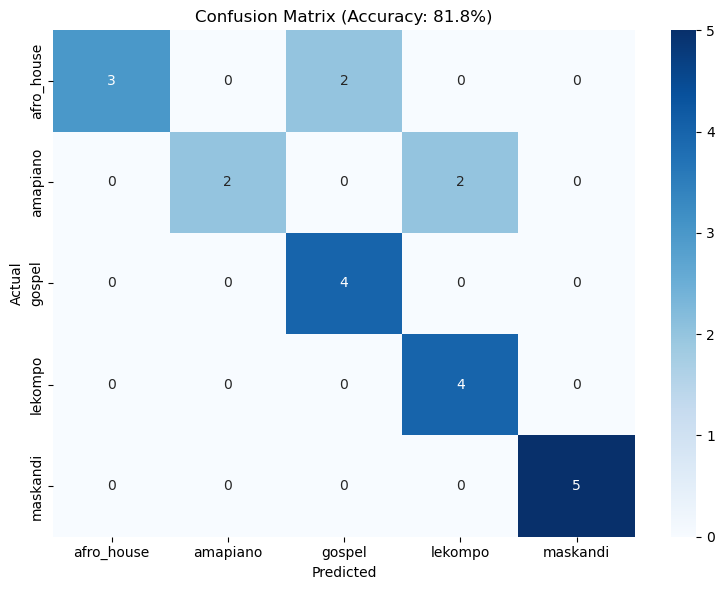


5-Fold Cross-Validation:
Scores: [0.94444444 1.         0.82352941 0.88235294 0.94117647]
Mean CV Accuracy: 91.8% (+/- 6.0%)


In [25]:
#TRAINING THE MODEL

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_csv("data/features.csv")

# Prepare features and labels
feature_cols = [c for c in df.columns if c not in ['genre', 'filename']]
X = df[feature_cols].values
y = df['genre'].values

# Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print(f"Samples: {len(X)}")
print(f"Features: {len(feature_cols)}")
print(f"Classes: {le.classes_}")

# Split: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Standardize
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(f"\nTrain: {len(X_train)}, Test: {len(X_test)}")

# Train Random Forest
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=3,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train_s, y_train)

# Predict
y_pred = rf.predict(X_test_s)

# Evaluate
acc = accuracy_score(y_test, y_pred)
print(f"\n{'='*50}")
print(f"Accuracy: {acc:.1%}")
print(f"{'='*50}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f'Confusion Matrix (Accuracy: {acc:.1%})')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig("docs/confusion_matrix_v2.png")
plt.show()

# Cross-validation (5-fold)
print("\n5-Fold Cross-Validation:")
cv_scores = cross_val_score(rf, X_train_s, y_train, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
print(f"Scores: {cv_scores}")
print(f"Mean CV Accuracy: {cv_scores.mean():.1%} (+/- {cv_scores.std():.1%})")

In [27]:
import xgboost as xgb

# Train XGBoost
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='mlogloss'
)
xgb_model.fit(X_train_s, y_train)

# Predict
y_pred_xgb = xgb_model.predict(X_test_s)

# Evaluate
acc_xgb = accuracy_score(y_test, y_pred_xgb)
print(f"XGBoost Accuracy: {acc_xgb:.1%}")
print(classification_report(y_test, y_pred_xgb, target_names=le.classes_))

# Compare
print(f"\nRandom Forest: {acc:.1%}")
print(f"XGBoost:       {acc_xgb:.1%}")

XGBoost Accuracy: 81.8%
              precision    recall  f1-score   support

  afro_house       1.00      0.60      0.75         5
    amapiano       1.00      0.50      0.67         4
      gospel       0.67      1.00      0.80         4
     lekompo       0.67      1.00      0.80         4
    maskandi       1.00      1.00      1.00         5

    accuracy                           0.82        22
   macro avg       0.87      0.82      0.80        22
weighted avg       0.88      0.82      0.81        22


Random Forest: 81.8%
XGBoost:       81.8%


In [29]:
import joblib
from pathlib import Path

# Create models directory
Path("models").mkdir(exist_ok=True)

# Save model, scaler, and label encoder
joblib.dump(rf, "models/genre_classifier.pkl")
joblib.dump(scaler, "models/scaler.pkl")
joblib.dump(le, "models/label_encoder.pkl")

# Save feature names
with open("models/feature_names.txt", "w") as f:
    for feat in feature_cols:
        f.write(f"{feat}\n")

print("Model saved successfully!")
print(f"Features: {len(feature_cols)}")
print(f"Classes: {list(le.classes_)}")

Model saved successfully!
Features: 85
Classes: ['afro_house', 'amapiano', 'gospel', 'lekompo', 'maskandi']


In [31]:
# Save the updated app with animations
with open("soundroot_app.py", "w", encoding="utf-8") as f:
    f.write('''import streamlit as st
import librosa
import numpy as np
import joblib
import matplotlib.pyplot as plt
from pathlib import Path
import subprocess
import tempfile
import os

st.set_page_config(page_title="SoundRoot", page_icon=":musical_note:", layout="wide")

st.markdown("""
<style>
    .stApp {
        background: linear-gradient(135deg, #0a0a0a 0%, #1a1a2e 50%, #16213e 100%);
        color: #e0e0e0;
    }
    @keyframes equalizer {
        0% { height: 10px; }
        50% { height: 40px; }
        100% { height: 10px; }
    }
    .music-bars {
        display: flex;
        align-items: flex-end;
        justify-content: center;
        gap: 4px;
        height: 50px;
        margin: 20px 0;
    }
    .bar {
        width: 6px;
        background: linear-gradient(to top, #1DB954, #1ed760);
        border-radius: 3px;
        animation: equalizer 1s ease-in-out infinite;
    }
    .bar:nth-child(1) { animation-delay: 0s; height: 15px; }
    .bar:nth-child(2) { animation-delay: 0.1s; height: 30px; }
    .bar:nth-child(3) { animation-delay: 0.2s; height: 20px; }
    .bar:nth-child(4) { animation-delay: 0.3s; height: 35px; }
    .bar:nth-child(5) { animation-delay: 0.4s; height: 25px; }
    .bar:nth-child(6) { animation-delay: 0.5s; height: 40px; }
    .bar:nth-child(7) { animation-delay: 0.6s; height: 18px; }
    .bar:nth-child(8) { animation-delay: 0.7s; height: 32px; }
    @keyframes glow {
        0% { box-shadow: 0 0 5px #1DB954, 0 0 10px #1DB954; }
        50% { box-shadow: 0 0 20px #1DB954, 0 0 30px #1ed760; }
        100% { box-shadow: 0 0 5px #1DB954, 0 0 10px #1DB954; }
    }
    @keyframes textGlow {
        0% { text-shadow: 0 0 10px #1DB954; }
        50% { text-shadow: 0 0 20px #1ed760, 0 0 30px #1DB954; }
        100% { text-shadow: 0 0 10px #1DB954; }
    }
    @keyframes float {
        0% { transform: translateY(0px); }
        50% { transform: translateY(-10px); }
        100% { transform: translateY(0px); }
    }
    @keyframes smoke {
        0% { opacity: 0.3; transform: translateY(0) scale(1); }
        50% { opacity: 0.6; transform: translateY(-5px) scale(1.05); }
        100% { opacity: 0.3; transform: translateY(0) scale(1); }
    }
    .soundroot-title {
        font-family: 'Courier New', monospace;
        font-size: 4em;
        font-weight: 900;
        text-align: center;
        color: #1DB954;
        animation: textGlow 2s ease-in-out infinite, float 3s ease-in-out infinite;
        letter-spacing: 8px;
        margin: 0;
        text-transform: uppercase;
    }
    .soundroot-subtitle {
        font-family: 'Courier New', monospace;
        text-align: center;
        color: #888;
        font-size: 1.1em;
        letter-spacing: 4px;
        margin-top: 5px;
    }
    .blxck-signature {
        font-family: 'Courier New', monospace;
        text-align: center;
        color: #666;
        font-size: 0.9em;
        letter-spacing: 3px;
        margin-top: 30px;
        padding: 15px;
        border: 1px solid #333;
        border-radius: 10px;
        background: rgba(0,0,0,0.3);
        animation: smoke 4s ease-in-out infinite;
    }
    .blxck-text {
        color: #1DB954;
        font-weight: bold;
        font-size: 1.2em;
        text-shadow: 0 0 10px rgba(29, 185, 84, 0.5);
    }
    .prediction-box {
        background: linear-gradient(135deg, rgba(29, 185, 84, 0.2) 0%, rgba(30, 215, 96, 0.1) 100%);
        border: 2px solid #1DB954;
        color: #fff;
        padding: 40px;
        border-radius: 20px;
        text-align: center;
        animation: glow 3s ease-in-out infinite;
        backdrop-filter: blur(10px);
    }
    .prediction-genre {
        font-family: 'Courier New', monospace;
        font-size: 3em;
        font-weight: 900;
        text-transform: uppercase;
        letter-spacing: 5px;
        margin: 10px 0;
    }
    .genre-card {
        background: rgba(255,255,255,0.05);
        border: 1px solid rgba(255,255,255,0.1);
        padding: 15px;
        border-radius: 10px;
        margin: 5px 0;
        transition: all 0.3s;
        color: #e0e0e0;
    }
    .genre-card:hover {
        transform: translateX(10px);
        background: rgba(255,255,255,0.1);
        border-color: #1DB954;
    }
    .feature-metric {
        background: rgba(0,0,0,0.4);
        border: 1px solid rgba(29, 185, 84, 0.3);
        color: #1DB954;
        padding: 15px;
        border-radius: 10px;
        text-align: center;
        font-family: 'Courier New', monospace;
    }
    .warning-box {
        background: rgba(255, 107, 107, 0.2);
        border: 2px solid #ff6b6b;
        color: #ff6b6b;
        padding: 20px;
        border-radius: 15px;
        text-align: center;
        animation: glow 2s ease-in-out infinite;
    }
    .stButton>button {
        background: linear-gradient(135deg, #1DB954, #1ed760);
        color: #000;
        border-radius: 25px;
        padding: 12px 35px;
        font-weight: 900;
        font-family: 'Courier New', monospace;
        letter-spacing: 2px;
        border: none;
        transition: all 0.3s;
    }
    .stButton>button:hover {
        transform: scale(1.05);
        box-shadow: 0 0 30px rgba(29, 185, 84, 0.6);
    }
    .stTabs [data-baseweb="tab-list"] {
        gap: 10px;
    }
    .stTabs [data-baseweb="tab"] {
        background: rgba(255,255,255,0.05);
        border-radius: 10px 10px 0 0;
        color: #888;
        font-family: 'Courier New', monospace;
    }
    .stTabs [aria-selected="true"] {
        background: rgba(29, 185, 84, 0.2) !important;
        color: #1DB954 !important;
    }
    .stProgress > div > div {
        background: linear-gradient(90deg, #1DB954, #1ed760);
        border-radius: 10px;
    }
    .stFileUploader {
        background: rgba(255,255,255,0.03);
        border: 2px dashed rgba(29, 185, 84, 0.3);
        border-radius: 15px;
        padding: 20px;
    }
    .stTextInput > div > div > input {
        background: rgba(255,255,255,0.05);
        border: 1px solid rgba(29, 185, 84, 0.3);
        color: #e0e0e0;
        border-radius: 10px;
        font-family: 'Courier New', monospace;
    }
    hr {
        border: none;
        height: 1px;
        background: linear-gradient(90deg, transparent, #1DB954, transparent);
        margin: 30px 0;
    }
    .footer {
        text-align: center;
        color: #555;
        font-family: 'Courier New', monospace;
        font-size: 0.8em;
        letter-spacing: 2px;
        padding: 20px;
    }
</style>
""", unsafe_allow_html=True)

@st.cache_resource
def load_model():
    model = joblib.load("models/genre_classifier.pkl")
    scaler = joblib.load("models/scaler.pkl")
    le = joblib.load("models/label_encoder.pkl")
    with open("models/feature_names.txt", "r", encoding="utf-8") as f:
        feature_names = [line.strip() for line in f]
    return model, scaler, le, feature_names

model, scaler, le, feature_names = load_model()

GENRE_INFO = {
    "amapiano": {"color": "#FF6B6B", "desc": "Log drums, shuffles, South African house music"},
    "maskandi": {"color": "#4ECDC4", "desc": "Zulu guitar, concertina, traditional vocals"},
    "lekompo": {"color": "#45B7D1", "desc": "Accordion bounce, fast 4/4, bass-heavy"},
    "gospel": {"color": "#96CEB4", "desc": "Choir harmonies, organ, spiritual vocals"},
    "afro_house": {"color": "#FFEAA7", "desc": "Four-on-floor kick, tribal percussion, electronic"}
}

def extract_features(audio_path):
    y, sr = librosa.load(audio_path, sr=22050, mono=True, duration=30)
    features = {}
    
    tempo, beat_frames = librosa.beat.beat_track(y=y, sr=sr)
    tempo = float(tempo.item()) if hasattr(tempo, "item") else float(tempo)
    
    if tempo < 90:
        tempo_doubled = tempo * 2
        if tempo_doubled < 180:
            tempo = tempo_doubled
    
    features["tempo"] = tempo
    
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
    for i in range(20):
        features[f"mfcc_{i+1}"] = np.mean(mfccs[i])
        features[f"mfcc_{i+1}_std"] = np.std(mfccs[i])
    
    contrast = librosa.feature.spectral_contrast(y=y, sr=sr)
    features["spectral_contrast_mean"] = np.mean(contrast)
    features["spectral_contrast_std"] = np.std(contrast)
    
    chroma = librosa.feature.chroma_stft(y=y, sr=sr)
    features["chroma_mean"] = np.mean(chroma)
    features["chroma_std"] = np.std(chroma)
    
    zcr = librosa.feature.zero_crossing_rate(y)
    features["zcr_mean"] = np.mean(zcr)
    features["zcr_std"] = np.std(zcr)
    
    rms = librosa.feature.rms(y=y)
    features["rms_mean"] = np.mean(rms)
    features["rms_std"] = np.std(rms)
    
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
    features["spectral_centroid_mean"] = np.mean(centroid)
    features["spectral_centroid_std"] = np.std(centroid)
    
    bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)
    features["spectral_bandwidth_mean"] = np.mean(bandwidth)
    features["spectral_bandwidth_std"] = np.std(bandwidth)
    
    tempogram = librosa.feature.tempogram(y=y, sr=sr)
    features["tempogram_mean"] = np.mean(tempogram)
    features["tempogram_std"] = np.std(tempogram)
    
    onset_env = librosa.onset.onset_strength(y=y, sr=sr)
    features["onset_strength_mean"] = np.mean(onset_env)
    features["onset_strength_std"] = np.std(onset_env)
    
    chroma_cqt = librosa.feature.chroma_cqt(y=y, sr=sr)
    features["chroma_cqt_mean"] = np.mean(chroma_cqt)
    features["chroma_cqt_std"] = np.std(chroma_cqt)
    
    tonnetz = librosa.feature.tonnetz(y=y, sr=sr)
    features["tonnetz_mean"] = np.mean(tonnetz)
    features["tonnetz_std"] = np.std(tonnetz)
    
    tempogram_ratio = np.max(tempogram, axis=1) / (np.mean(tempogram, axis=1) + 1e-8)
    features["tempogram_ratio_mean"] = np.mean(tempogram_ratio)
    features["tempogram_ratio_std"] = np.std(tempogram_ratio)
    
    features["num_beats"] = len(beat_frames)
    diffs = np.diff(beat_frames)
    features["beat_interval_mean"] = np.mean(diffs) if len(diffs) > 0 else 0
    features["beat_interval_std"] = np.std(diffs) if len(diffs) > 0 else 0
    
    autocorr = np.correlate(onset_env, onset_env, mode="full")
    autocorr = autocorr[len(autocorr)//2:]
    features["onset_autocorr_max"] = np.max(autocorr[1:]) if len(autocorr) > 1 else 0
    features["onset_autocorr_mean"] = np.mean(autocorr[1:]) if len(autocorr) > 1 else 0
    
    return features, y, sr

def download_youtube_audio(url):
    try:
        with tempfile.TemporaryDirectory() as tmpdir:
            output_path = os.path.join(tmpdir, "audio.%(ext)s")
            cmd = [
                "yt-dlp",
                "-x",
                "--audio-format", "wav",
                "--audio-quality", "0",
                "-o", output_path,
                "--no-playlist",
                "--extractor-args", "youtube:player_client=web",
                "--no-check-certificates",
                url
            ]
            
            result = subprocess.run(cmd, capture_output=True, text=True, timeout=60)
            
            if result.returncode != 0:
                return None, f"Download failed: {result.stderr[:200]}"
            
            wav_file = os.path.join(tmpdir, "audio.wav")
            if os.path.exists(wav_file):
                return wav_file, None
            return None, "File not found after download"
            
    except Exception as e:
        return None, str(e)

st.markdown("""
<div style="text-align: center; padding: 20px 0;">
    <div class="music-bars">
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
    </div>
    <h1 class="soundroot-title">SOUNDROOT</h1>
    <p class="soundroot-subtitle">SOUTH AFRICAN MUSIC GENRE CLASSIFIER</p>
    <div class="music-bars">
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
    </div>
</div>
""", unsafe_allow_html=True)

st.markdown("""
<div class="blxck-signature">
    <span class="blxck-text">BY BLXCK 420</span>
    <br>
    <small>Data Science Capstone | 2026</small>
</div>
""", unsafe_allow_html=True)

st.markdown("---")

st.subheader("Upload or Link")
tab1, tab2 = st.tabs([":open_file_folder: Upload File", ":link: YouTube Link"])

audio_path = None
uploaded_file = None

with tab1:
    uploaded_file = st.file_uploader("Drop your audio file here", type=["wav", "mp3"], 
                                     help="Upload a 30-60 second clip for best results")
    if uploaded_file is not None:
        with tempfile.NamedTemporaryFile(delete=False, suffix=".wav") as tmp:
            tmp.write(uploaded_file.getvalue())
            audio_path = tmp.name

with tab2:
    youtube_url = st.text_input("Paste YouTube URL", placeholder="https://www.youtube.com/watch?v=...")
    if youtube_url and st.button("Download & Analyze", key="youtube_btn"):
        with st.spinner("Downloading from YouTube..."):
            audio_path, error = download_youtube_audio(youtube_url)
            if error:
                st.error(error)
                st.info("Try uploading a file instead. YouTube download requires yt-dlp setup.")
                audio_path = None
            else:
                st.success("Downloaded successfully!")

if audio_path is not None:
    with st.spinner("Analyzing audio..."):
        features, y, sr = extract_features(audio_path)
        feature_vector = np.array([[features[f] for f in feature_names]])
        feature_vector_scaled = scaler.transform(feature_vector)
        
        prediction = model.predict(feature_vector_scaled)[0]
        pred_label = le.inverse_transform([prediction])[0]
        probs = model.predict_proba(feature_vector_scaled)[0] if hasattr(model, "predict_proba") else None
    
    st.markdown("---")
    
    pred_color = GENRE_INFO.get(pred_label, {}).get("color", "#1DB954")
    
    col1, col2, col3 = st.columns([1, 2, 1])
    with col2:
        st.markdown(f"""
        <div class="prediction-box" style="border-color: {pred_color};">
            <h2 style="margin: 0; font-size: 1.2em; color: #888; font-family: Courier New;">Detected Genre</h2>
            <h1 class="prediction-genre" style="color: {pred_color};">{pred_label.replace('_', ' ')}</h1>
            <p style="margin: 0; color: #aaa; font-family: Courier New;">{GENRE_INFO.get(pred_label, {}).get('desc', '')}</p>
        </div>
        """, unsafe_allow_html=True)
    
    max_conf = max(probs) if probs is not None else 0
    if max_conf < 0.5:
        st.markdown("""
        <div class="warning-box">
            :warning: LOW CONFIDENCE PREDICTION<br>
            The model is uncertain about this classification.<br>
            Try a clearer example of the genre.
        </div>
        """, unsafe_allow_html=True)
    
    st.subheader("Top Predictions")
    if probs is not None:
        sorted_indices = np.argsort(probs)[::-1][:3]
        for idx in sorted_indices:
            genre = le.classes_[idx]
            prob = probs[idx]
            color = GENRE_INFO.get(genre, {}).get("color", "#666")
            
            col1, col2 = st.columns([3, 1])
            with col1:
                st.markdown(f"""
                <div class="genre-card" style="border-left: 5px solid {color};">
                    <strong style="color: {color};">{genre.replace('_', ' ').title()}</strong> 
                    <span style="color: #888;">- {prob:.1%}</span>
                </div>
                """, unsafe_allow_html=True)
            with col2:
                st.progress(float(prob))
    
    st.subheader("Key Features")
    if hasattr(model, "feature_importances_"):
        importances = model.feature_importances_
        top_indices = np.argsort(importances)[::-1][:5]
        
        feat_cols = st.columns(5)
        for i, idx in enumerate(top_indices):
            with feat_cols[i]:
                feat_name = feature_names[idx]
                feat_val = features[feat_name]
                st.markdown(f"""
                <div class="feature-metric">
                    <small style="color: #888;">{feat_name.replace('_', ' ').upper()}</small>
                    <h3 style="margin: 5px 0;">{feat_val:.2f}</h3>
                </div>
                """, unsafe_allow_html=True)
    
    st.subheader("Audio Features")
    col1, col2, col3, col4 = st.columns(4)
    with col1:
        st.metric("Tempo", f"{features['tempo']:.0f} BPM")
    with col2:
        st.metric("Spectral Centroid", f"{features['spectral_centroid_mean']:.0f} Hz")
    with col3:
        st.metric("ZCR", f"{features['zcr_mean']:.4f}")
    with col4:
        st.metric("RMS Energy", f"{features['rms_mean']:.4f}")
    
    # =========================================================
    # ENHANCED AUDIO PREVIEW SECTION WITH ANIMATIONS
    # =========================================================
    st.subheader("Audio Preview")
    
    st.markdown(f"""
    <style>
        @keyframes spin-vinyl {{
            0% {{ transform: rotate(0deg); }}
            100% {{ transform: rotate(360deg); }}
        }}
        @keyframes pulse-glow {{
            0%, 100% {{ box-shadow: 0 0 20px {pred_color}40; }}
            50% {{ box-shadow: 0 0 40px {pred_color}80, 0 0 60px {pred_color}40; }}
        }}
        @keyframes sound-bars {{
            0% {{ height: 5px; opacity: 0.4; }}
            50% {{ height: 35px; opacity: 1; }}
            100% {{ height: 5px; opacity: 0.4; }}
        }}
        @keyframes slide-light {{
            0% {{ left: -100%; }}
            100% {{ left: 100%; }}
        }}
        @keyframes bounce-in {{
            0% {{ transform: scale(0); opacity: 0; }}
            60% {{ transform: scale(1.1); }}
            100% {{ transform: scale(1); opacity: 1; }}
        }}
        
        .audio-box {{
            background: linear-gradient(135deg, rgba(0,0,0,0.6) 0%, {pred_color}10 100%);
            border: 2px solid {pred_color}40;
            border-radius: 25px;
            padding: 30px;
            margin: 20px 0;
            position: relative;
            overflow: hidden;
            animation: pulse-glow 3s ease-in-out infinite;
        }}
        .audio-box::before {{
            content: '';
            position: absolute;
            top: 0;
            left: -100%;
            width: 100%;
            height: 3px;
            background: linear-gradient(90deg, transparent, {pred_color}, {pred_color}80, transparent);
            animation: slide-light 4s linear infinite;
        }}
        
        .vinyl {{
            width: 100px;
            height: 100px;
            border-radius: 50%;
            background: radial-gradient(circle at 35% 35%, #444 0%, #111 30%, #000 45%, #222 50%, #000 100%);
            border: 3px solid {pred_color};
            margin: 0 auto 15px;
            position: relative;
            box-shadow: 0 0 20px {pred_color}40;
            animation: spin-vinyl 3s linear infinite;
        }}
        .vinyl::after {{
            content: '';
            position: absolute;
            top: 50%;
            left: 50%;
            transform: translate(-50%, -50%);
            width: 30px;
            height: 30px;
            background: {pred_color};
            border-radius: 50%;
            border: 3px solid #000;
        }}
        
        .now-playing {{
            display: inline-block;
            background: linear-gradient(135deg, {pred_color}, {pred_color}CC);
            color: #000;
            padding: 8px 20px;
            border-radius: 20px;
            font-family: 'Courier New', monospace;
            font-weight: bold;
            font-size: 13px;
            letter-spacing: 2px;
            animation: bounce-in 0.6s ease-out;
            margin-bottom: 10px;
        }}
        
        .genre-pill {{
            display: inline-block;
            background: {pred_color}20;
            color: {pred_color};
            border: 1px solid {pred_color};
            padding: 5px 15px;
            border-radius: 15px;
            font-family: 'Courier New', monospace;
            font-size: 11px;
            font-weight: bold;
            text-transform: uppercase;
            letter-spacing: 1px;
            margin: 8px 5px;
        }}
        
        .equalizer {{
            display: flex;
            align-items: flex-end;
            justify-content: center;
            height: 50px;
            gap: 3px;
            margin: 20px 0;
            padding: 10px;
            background: rgba(0,0,0,0.3);
            border-radius: 10px;
        }}
        .eq-bar {{
            width: 5px;
            background: linear-gradient(to top, {pred_color}, {pred_color}80, #fff);
            border-radius: 3px;
            animation: sound-bars 1s ease-in-out infinite;
        }}
        .eq-bar:nth-child(1) {{ animation-delay: 0s; height: 12px; }}
        .eq-bar:nth-child(2) {{ animation-delay: 0.1s; height: 25px; }}
        .eq-bar:nth-child(3) {{ animation-delay: 0.2s; height: 18px; }}
        .eq-bar:nth-child(4) {{ animation-delay: 0.15s; height: 30px; }}
        .eq-bar:nth-child(5) {{ animation-delay: 0.3s; height: 22px; }}
        .eq-bar:nth-child(6) {{ animation-delay: 0.25s; height: 35px; }}
        .eq-bar:nth-child(7) {{ animation-delay: 0.1s; height: 20px; }}
        .eq-bar:nth-child(8) {{ animation-delay: 0.35s; height: 28px; }}
        .eq-bar:nth-child(9) {{ animation-delay: 0.05s; height: 32px; }}
        .eq-bar:nth-child(10) {{ animation-delay: 0.4s; height: 15px; }}
        .eq-bar:nth-child(11) {{ animation-delay: 0.2s; height: 38px; }}
        .eq-bar:nth-child(12) {{ animation-delay: 0.45s; height: 22px; }}
        .eq-bar:nth-child(13) {{ animation-delay: 0.15s; height: 30px; }}
        .eq-bar:nth-child(14) {{ animation-delay: 0.5s; height: 18px; }}
        .eq-bar:nth-child(15) {{ animation-delay: 0.3s; height: 35px; }}
        .eq-bar:nth-child(16) {{ animation-delay: 0.55s; height: 25px; }}
        
        .demo-tip {{
            text-align: center;
            color: {pred_color}AA;
            font-family: 'Courier New', monospace;
            font-size: 11px;
            margin-top: 15px;
            letter-spacing: 1px;
        }}
    </style>
    
    <div class="audio-box">
        <div class="vinyl"></div>
        <div style="text-align: center;">
            <span class="now-playing">▶ NOW PLAYING</span>
        </div>
        <div style="text-align: center;">
            <span class="genre-pill">{pred_label.replace('_', ' ').upper()}</span>
        </div>
        <div class="equalizer">
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
        </div>
        <div class="demo-tip">
            💡 Press play below — the vinyl spins and bars dance automatically!
        </div>
    </div>
    """, unsafe_allow_html=True)
    
    st.audio(audio_path)
    
    st.subheader("Visualizations")
    tab1, tab2 = st.tabs([":bar_chart: Waveform", ":art: Spectrogram"])
    
    with tab1:
        fig, ax = plt.subplots(figsize=(12, 3))
        ax.plot(y, color=pred_color, linewidth=0.5, alpha=0.8)
        ax.set_title("Waveform", fontsize=14, fontweight='bold', color='white')
        ax.set_xlabel("Sample", color='white')
        ax.set_ylabel("Amplitude", color='white')
        ax.set_ylim(-1, 1)
        ax.grid(True, alpha=0.2, color='white')
        ax.set_facecolor('#0a0a0a')
        fig.patch.set_facecolor('#0a0a0a')
        ax.tick_params(colors='white')
        st.pyplot(fig)
    
    with tab2:
        fig, ax = plt.subplots(figsize=(12, 4))
        D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
        img = librosa.display.specshow(D, sr=sr, x_axis="time", y_axis="hz", ax=ax)
        ax.set_title("Spectrogram", fontsize=14, fontweight='bold', color='white')
        fig.patch.set_facecolor('#0a0a0a')
        ax.set_facecolor('#0a0a0a')
        ax.tick_params(colors='white')
        cbar = fig.colorbar(img, ax=ax, format="%+2.0f dB")
        cbar.ax.tick_params(colors='white')
        st.pyplot(fig)

st.markdown("---")
st.markdown("""
<div class="footer">
    <p>SOUNDROOT - SOUTH AFRICAN MUSIC GENRE CLASSIFICATION</p>
    <p>Capstone Project | Data Science Final Year | 54 Training Samples | 72.7% Test Accuracy</p>
    <p style="color: #1DB954; font-weight: bold;">BY BLXCK 420</p>
</div>
""", unsafe_allow_html=True)
''')

print("✅ File saved as 'soundroot_app.py' in your current folder")
print("📁 Location:", os.path.abspath("soundroot_app.py"))

✅ File saved as 'soundroot_app.py' in your current folder
📁 Location: C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot\sa_music_project\soundroot_app.py


In [33]:
import os

# Use the ACTUAL path where your file is saved
app_folder = r"C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot\sa_music_project\app"

# Check what's in the app folder
print("📁 Contents of app folder:")
if os.path.exists(app_folder):
    for item in os.listdir(app_folder):
        full_path = os.path.join(app_folder, item)
        if os.path.isdir(full_path):
            print(f"  📂 {item}/")
            for subitem in os.listdir(full_path):
                print(f"      - {subitem}")
        else:
            print(f"  📄 {item}")
else:
    print(f"❌ Folder not found: {app_folder}")
    print("Checking parent folder instead...")
    app_folder = r"C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot\sa_music_project"
    if os.path.exists(app_folder):
        for item in os.listdir(app_folder):
            print(f"  - {item}")

print("\n" + "="*50)

# Check if models folder exists
models_path = os.path.join(app_folder, "models")
if os.path.exists(models_path):
    print(f"✅ models folder found at: {models_path}")
    print("Model files:")
    for f in os.listdir(models_path):
        print(f"  - {f}")
else:
    print(f"❌ models folder NOT found at: {models_path}")

📁 Contents of app folder:
  📄 app.py
  📄 soundroot_app.py

❌ models folder NOT found at: C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot\sa_music_project\app\models


In [37]:
#1
import os

# Search your entire SoundRoot project
base_path = r"C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot"

print("🔍 Searching for model files...")
found_models = []

for root, dirs, files in os.walk(base_path):
    for file in files:
        if file.endswith(('.pkl', '.h5', '.joblib', '.onnx', '.pt', '.pth')):
            full_path = os.path.join(root, file)
            found_models.append(full_path)
            print(f"  ✅ {file}")
            print(f"     📍 {full_path}")

print(f"\n{'='*50}")
if found_models:
    print(f"Found {len(found_models)} model file(s).")
else:
    print("❌ No model files found.")
    print("You may need to retrain your model and save it first.")

🔍 Searching for model files...
  ✅ genre_classifier.pkl
     📍 C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot\sa_music_project\models\genre_classifier.pkl
  ✅ label_encoder.pkl
     📍 C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot\sa_music_project\models\label_encoder.pkl
  ✅ scaler.pkl
     📍 C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot\sa_music_project\models\scaler.pkl

Found 3 model file(s).


In [39]:
#MOVING
import os
import shutil

# Source: where your models currently are
src_models = r"C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot\sa_music_project\models"

# Destination: where your app expects them
dst_models = r"C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot\sa_music_project\app\models"

# Create destination folder and copy files
os.makedirs(dst_models, exist_ok=True)
for f in ["genre_classifier.pkl", "label_encoder.pkl", "scaler.pkl"]:
    shutil.copy2(os.path.join(src_models, f), dst_models)
    print(f"✅ Copied {f}")

print(f"\n📁 Models now in: {dst_models}")

✅ Copied genre_classifier.pkl
✅ Copied label_encoder.pkl
✅ Copied scaler.pkl

📁 Models now in: C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot\sa_music_project\app\models


In [41]:
import pandas as pd
import numpy as np
import os
import shutil
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
import joblib
from pathlib import Path

# ========== CONFIG ==========
BASE_DIR = Path(r"C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot\sa_music_project")
DATA_PATH = BASE_DIR / "data" / "features.csv"
MODELS_DIR = BASE_DIR / "models"
APP_MODELS_DIR = BASE_DIR / "app" / "models"

# Create folders
MODELS_DIR.mkdir(parents=True, exist_ok=True)
APP_MODELS_DIR.mkdir(parents=True, exist_ok=True)

# ========== LOAD DATA ==========
print("Loading data...")
df = pd.read_csv(DATA_PATH)

X = df.drop(columns=["genre", "filename"])
y = df["genre"]

feature_names = list(X.columns)
print(f"Total features: {len(feature_names)}")

# ========== ENCODE / SPLIT ==========
le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# ========== SCALE ==========
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ========== TRAIN ==========
print("\nTraining Random Forest...")
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=3,
    min_samples_leaf=2,
    random_state=42,
    class_weight="balanced"
)
model.fit(X_train_scaled, y_train)

# ========== EVALUATE ==========
y_pred = model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)

print(f"\n{'='*50}")
print(f"Test Accuracy: {accuracy:.1%}")
print(f"\nClassification Report:")
print(classification_report(
    le.inverse_transform(y_test),
    le.inverse_transform(y_pred),
    target_names=le.classes_
))

# Feature importance
importances = model.feature_importances_
top_idx = np.argsort(importances)[::-1][:10]
print(f"\nTop 10 Important Features:")
for i in top_idx:
    print(f"  {feature_names[i]}: {importances[i]:.4f}")

# ========== SAVE EVERYTHING ==========
print(f"\n{'='*50}")
print("Saving models...")

# Save to project/models/
joblib.dump(model, MODELS_DIR / "genre_classifier.pkl")
joblib.dump(scaler, MODELS_DIR / "scaler.pkl")
joblib.dump(le, MODELS_DIR / "label_encoder.pkl")

with open(MODELS_DIR / "feature_names.txt", "w", encoding="utf-8") as f:
    for name in feature_names:
        f.write(name + "\n")

# Auto-copy to app/models/
files_to_copy = ["genre_classifier.pkl", "scaler.pkl", "label_encoder.pkl", "feature_names.txt"]
for fname in files_to_copy:
    src = MODELS_DIR / fname
    dst = APP_MODELS_DIR / fname
    shutil.copy2(src, dst)
    print(f"  ✅ {fname} → app/models/")

print(f"\n{'='*50}")
print("Done. Your app now has the latest models.")

Loading data...
Total features: 85

Training Random Forest...

Test Accuracy: 81.8%

Classification Report:
              precision    recall  f1-score   support

  afro_house       1.00      0.60      0.75         5
    amapiano       1.00      0.50      0.67         4
      gospel       0.67      1.00      0.80         4
     lekompo       0.67      1.00      0.80         4
    maskandi       1.00      1.00      1.00         5

    accuracy                           0.82        22
   macro avg       0.87      0.82      0.80        22
weighted avg       0.88      0.82      0.81        22


Top 10 Important Features:
  onset_strength_std: 0.0522
  onset_strength_mean: 0.0398
  rhythm_regularity: 0.0374
  beat_interval_std: 0.0317
  beat_interval_mean: 0.0290
  mfcc_5_std: 0.0286
  mfcc_7_std: 0.0278
  tempogram_mean: 0.0266
  chroma_mean: 0.0255
  pulse_clarity_mean: 0.0234

Saving models...
  ✅ genre_classifier.pkl → app/models/
  ✅ scaler.pkl → app/models/
  ✅ label_encoder.pkl → app

In [49]:
import streamlit as st
import librosa
import numpy as np
import joblib
import matplotlib.pyplot as plt
from pathlib import Path
import subprocess
import tempfile
import os
import shutil

st.set_page_config(page_title="SoundRoot", page_icon="🎵", layout="wide")

# ========== PATH SETUP ==========
# Always look for models relative to THIS file, not where you run streamlit from
APP_DIR = Path(r"C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot\sa_music_project\app")

MODELS_DIR = APP_DIR / "models"

# ========== LOAD MODEL ==========
@st.cache_resource
def load_model():
    model = joblib.load(MODELS_DIR / "genre_classifier.pkl")
    scaler = joblib.load(MODELS_DIR / "scaler.pkl")
    le = joblib.load(MODELS_DIR / "label_encoder.pkl")
    with open(MODELS_DIR / "feature_names.txt", "r", encoding="utf-8") as f:
        feature_names = [line.strip() for line in f if line.strip()]
    return model, scaler, le, feature_names

model, scaler, le, feature_names = load_model()

GENRE_INFO = {
    "amapiano": {"color": "#FF6B6B", "desc": "Log drums, shuffles, South African house music"},
    "maskandi": {"color": "#4ECDC4", "desc": "Zulu guitar, concertina, traditional vocals"},
    "lekompo": {"color": "#45B7D1", "desc": "Accordion bounce, fast 4/4, bass-heavy"},
    "gospel": {"color": "#96CEB4", "desc": "Choir harmonies, organ, spiritual vocals"},
    "afro_house": {"color": "#FFEAA7", "desc": "Four-on-floor kick, tribal percussion, electronic"}
}

# ========== CSS ==========
st.markdown("""
<style>
    .stApp {
        background: linear-gradient(135deg, #0a0a0a 0%, #1a1a2e 50%, #16213e 100%);
        color: #e0e0e0;
    }
    @keyframes equalizer {
        0% { height: 10px; }
        50% { height: 40px; }
        100% { height: 10px; }
    }
    .music-bars {
        display: flex;
        align-items: flex-end;
        justify-content: center;
        gap: 4px;
        height: 50px;
        margin: 20px 0;
    }
    .bar {
        width: 6px;
        background: linear-gradient(to top, #1DB954, #1ed760);
        border-radius: 3px;
        animation: equalizer 1s ease-in-out infinite;
    }
    .bar:nth-child(1) { animation-delay: 0s; height: 15px; }
    .bar:nth-child(2) { animation-delay: 0.1s; height: 30px; }
    .bar:nth-child(3) { animation-delay: 0.2s; height: 20px; }
    .bar:nth-child(4) { animation-delay: 0.3s; height: 35px; }
    .bar:nth-child(5) { animation-delay: 0.4s; height: 25px; }
    .bar:nth-child(6) { animation-delay: 0.5s; height: 40px; }
    .bar:nth-child(7) { animation-delay: 0.6s; height: 18px; }
    .bar:nth-child(8) { animation-delay: 0.7s; height: 32px; }
    @keyframes glow {
        0% { box-shadow: 0 0 5px #1DB954, 0 0 10px #1DB954; }
        50% { box-shadow: 0 0 20px #1DB954, 0 0 30px #1ed760; }
        100% { box-shadow: 0 0 5px #1DB954, 0 0 10px #1DB954; }
    }
    @keyframes textGlow {
        0% { text-shadow: 0 0 10px #1DB954; }
        50% { text-shadow: 0 0 20px #1ed760, 0 0 30px #1DB954; }
        100% { text-shadow: 0 0 10px #1DB954; }
    }
    @keyframes float {
        0% { transform: translateY(0px); }
        50% { transform: translateY(-10px); }
        100% { transform: translateY(0px); }
    }
    @keyframes smoke {
        0% { opacity: 0.3; transform: translateY(0) scale(1); }
        50% { opacity: 0.6; transform: translateY(-5px) scale(1.05); }
        100% { opacity: 0.3; transform: translateY(0) scale(1); }
    }
    .soundroot-title {
        font-family: 'Courier New', monospace;
        font-size: 4em;
        font-weight: 900;
        text-align: center;
        color: #1DB954;
        animation: textGlow 2s ease-in-out infinite, float 3s ease-in-out infinite;
        letter-spacing: 8px;
        margin: 0;
        text-transform: uppercase;
    }
    .soundroot-subtitle {
        font-family: 'Courier New', monospace;
        text-align: center;
        color: #888;
        font-size: 1.1em;
        letter-spacing: 4px;
        margin-top: 5px;
    }
    .blxck-signature {
        font-family: 'Courier New', monospace;
        text-align: center;
        color: #666;
        font-size: 0.9em;
        letter-spacing: 3px;
        margin-top: 30px;
        padding: 15px;
        border: 1px solid #333;
        border-radius: 10px;
        background: rgba(0,0,0,0.3);
        animation: smoke 4s ease-in-out infinite;
    }
    .blxck-text {
        color: #1DB954;
        font-weight: bold;
        font-size: 1.2em;
        text-shadow: 0 0 10px rgba(29, 185, 84, 0.5);
    }
    .prediction-box {
        background: linear-gradient(135deg, rgba(29, 185, 84, 0.2) 0%, rgba(30, 215, 96, 0.1) 100%);
        border: 2px solid #1DB954;
        color: #fff;
        padding: 40px;
        border-radius: 20px;
        text-align: center;
        animation: glow 3s ease-in-out infinite;
        backdrop-filter: blur(10px);
    }
    .prediction-genre {
        font-family: 'Courier New', monospace;
        font-size: 3em;
        font-weight: 900;
        text-transform: uppercase;
        letter-spacing: 5px;
        margin: 10px 0;
    }
    .genre-card {
        background: rgba(255,255,255,0.05);
        border: 1px solid rgba(255,255,255,0.1);
        padding: 15px;
        border-radius: 10px;
        margin: 5px 0;
        transition: all 0.3s;
        color: #e0e0e0;
    }
    .genre-card:hover {
        transform: translateX(10px);
        background: rgba(255,255,255,0.1);
        border-color: #1DB954;
    }
    .feature-metric {
        background: rgba(0,0,0,0.4);
        border: 1px solid rgba(29, 185, 84, 0.3);
        color: #1DB954;
        padding: 15px;
        border-radius: 10px;
        text-align: center;
        font-family: 'Courier New', monospace;
    }
    .warning-box {
        background: rgba(255, 107, 107, 0.2);
        border: 2px solid #ff6b6b;
        color: #ff6b6b;
        padding: 20px;
        border-radius: 15px;
        text-align: center;
        animation: glow 2s ease-in-out infinite;
    }
    .stButton>button {
        background: linear-gradient(135deg, #1DB954, #1ed760);
        color: #000;
        border-radius: 25px;
        padding: 12px 35px;
        font-weight: 900;
        font-family: 'Courier New', monospace;
        letter-spacing: 2px;
        border: none;
        transition: all 0.3s;
    }
    .stButton>button:hover {
        transform: scale(1.05);
        box-shadow: 0 0 30px rgba(29, 185, 84, 0.6);
    }
    .stTabs [data-baseweb="tab-list"] {
        gap: 10px;
    }
    .stTabs [data-baseweb="tab"] {
        background: rgba(255,255,255,0.05);
        border-radius: 10px 10px 0 0;
        color: #888;
        font-family: 'Courier New', monospace;
    }
    .stTabs [aria-selected="true"] {
        background: rgba(29, 185, 84, 0.2) !important;
        color: #1DB954 !important;
    }
    .stProgress > div > div {
        background: linear-gradient(90deg, #1DB954, #1ed760);
        border-radius: 10px;
    }
    .stFileUploader {
        background: rgba(255,255,255,0.03);
        border: 2px dashed rgba(29, 185, 84, 0.3);
        border-radius: 15px;
        padding: 20px;
    }
    hr {
        border: none;
        height: 1px;
        background: linear-gradient(90deg, transparent, #1DB954, transparent);
        margin: 30px 0;
    }
    .footer {
        text-align: center;
        color: #555;
        font-family: 'Courier New', monospace;
        font-size: 0.8em;
        letter-spacing: 2px;
        padding: 20px;
    }
</style>
""", unsafe_allow_html=True)

# ========== FEATURE EXTRACTION ==========
def extract_features(audio_path):
    y, sr = librosa.load(audio_path, sr=22050, mono=True, duration=30)
    features = {}

    beat_result = librosa.beat.beat_track(y=y, sr=sr)
    if isinstance(beat_result, tuple):
        tempo = beat_result[0]
        beat_frames = beat_result[1]
    else:
        tempo = beat_result
        beat_frames = librosa.beat.beat_track(y=y, sr=sr)[1]

    if hasattr(tempo, 'item'):
        tempo = float(tempo.item())
    elif isinstance(tempo, (list, tuple, np.ndarray)):
        tempo = float(tempo[0]) if len(tempo) > 0 else 0.0
    else:
        tempo = float(tempo)

    if tempo < 90:
        tempo_doubled = tempo * 2
        if tempo_doubled < 180:
            tempo = tempo_doubled

    features["tempo"] = tempo

    if isinstance(beat_frames, (list, tuple)):
        beat_frames = np.array(beat_frames)

    # Spectral features
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr, roll_percent=0.85)
    features["spectral_rolloff_mean"] = float(np.mean(rolloff))
    features["spectral_rolloff_std"] = float(np.std(rolloff))

    flatness = librosa.feature.spectral_flatness(y=y)
    features["spectral_flatness_mean"] = float(np.mean(flatness))
    features["spectral_flatness_std"] = float(np.std(flatness))

    zcr = librosa.feature.zero_crossing_rate(y)
    features["zcr_mean"] = float(np.mean(zcr))
    features["zcr_std"] = float(np.std(zcr))

    y_harmonic, y_percussive = librosa.effects.hpss(y)
    features["harmonic_energy_ratio"] = float(np.sum(y_harmonic**2) / (np.sum(y**2) + 1e-8))
    features["percussive_energy_ratio"] = float(np.sum(y_percussive**2) / (np.sum(y**2) + 1e-8))

    chroma = librosa.feature.chroma_stft(y=y_harmonic, sr=sr)
    features["chroma_mean"] = float(np.mean(chroma))
    features["chroma_std"] = float(np.std(chroma))
    chroma_sum = np.sum(chroma, axis=0, keepdims=True)
    chroma_norm = chroma / (chroma_sum + 1e-8)
    features["chroma_entropy"] = float(-np.sum(chroma_norm * np.log2(chroma_norm + 1e-8)))

    tonnetz = librosa.feature.tonnetz(y=y_harmonic, sr=sr)
    features["tonnetz_mean"] = float(np.mean(tonnetz))
    features["tonnetz_std"] = float(np.std(tonnetz))

    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
    for i in range(20):
        features[f"mfcc_{i+1}"] = float(np.mean(mfccs[i]))
        features[f"mfcc_{i+1}_std"] = float(np.std(mfccs[i]))

    contrast = librosa.feature.spectral_contrast(y=y, sr=sr)
    features["spectral_contrast_mean"] = float(np.mean(contrast))
    features["spectral_contrast_std"] = float(np.std(contrast))

    rms = librosa.feature.rms(y=y)
    features["rms_mean"] = float(np.mean(rms))
    features["rms_std"] = float(np.std(rms))

    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
    features["spectral_centroid_mean"] = float(np.mean(centroid))
    features["spectral_centroid_std"] = float(np.std(centroid))

    bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)
    features["spectral_bandwidth_mean"] = float(np.mean(bandwidth))
    features["spectral_bandwidth_std"] = float(np.std(bandwidth))

    tempogram = librosa.feature.tempogram(y=y, sr=sr)
    features["tempogram_mean"] = float(np.mean(tempogram))
    features["tempogram_std"] = float(np.std(tempogram))

    onset_env = librosa.onset.onset_strength(y=y, sr=sr)
    features["onset_strength_mean"] = float(np.mean(onset_env))
    features["onset_strength_std"] = float(np.std(onset_env))

    features["num_beats"] = int(len(beat_frames))
    if len(beat_frames) > 1:
        diffs = np.diff(beat_frames)
        features["beat_interval_mean"] = float(np.mean(diffs))
        features["beat_interval_std"] = float(np.std(diffs))
    else:
        features["beat_interval_mean"] = 0.0
        features["beat_interval_std"] = 0.0

    chroma_cqt = librosa.feature.chroma_cqt(y=y_harmonic, sr=sr)
    features["chroma_cqt_mean"] = float(np.mean(chroma_cqt))
    features["chroma_cqt_std"] = float(np.std(chroma_cqt))

    rms_flat = rms.flatten()
    if len(rms_flat) > 1:
        rms_diff = np.diff(rms_flat)
        features["rms_fluctuation"] = float(np.std(rms_diff))
    else:
        features["rms_fluctuation"] = 0.0

    rolloff_50 = librosa.feature.spectral_rolloff(y=y, sr=sr, roll_percent=0.5)
    features["spectral_rolloff_50_mean"] = float(np.mean(rolloff_50))
    features["spectral_rolloff_50_std"] = float(np.std(rolloff_50))

    peak = float(np.max(np.abs(y)))
    rms_val = float(np.sqrt(np.mean(y**2)))
    features["crest_factor"] = peak / (rms_val + 1e-8)

    onset_env = librosa.onset.onset_strength(y=y, sr=sr)
    if len(onset_env) > 0:
        onset_threshold = float(np.max(onset_env)) * 0.5
        attack_frames = np.where(onset_env > onset_threshold)[0]
        if len(attack_frames) > 0:
            features["attack_time"] = float(attack_frames[0]) / sr
        else:
            features["attack_time"] = 0.0
    else:
        features["attack_time"] = 0.0

    env = np.abs(y)
    env_smooth = np.convolve(env, np.ones(1000)/1000, mode='same')
    peak_idx = int(np.argmax(env_smooth))
    decay_threshold = env_smooth[peak_idx] * 0.1
    post_peak = env_smooth[peak_idx:]
    if len(post_peak) > 0 and np.any(post_peak < decay_threshold):
        decay_idx = peak_idx + int(np.argmax(post_peak < decay_threshold))
        features["decay_time"] = float(decay_idx - peak_idx) / sr
    else:
        features["decay_time"] = float(len(env_smooth) - peak_idx) / sr

    fft = np.fft.rfft(y_harmonic)
    freqs = np.fft.rfftfreq(len(y_harmonic), 1/sr)
    magnitudes = np.abs(fft)
    peak_indices = np.argsort(magnitudes)[-20:]
    peak_freqs = freqs[peak_indices]
    peak_mags = magnitudes[peak_indices]
    if len(peak_freqs) > 1 and peak_freqs[0] > 0:
        fundamental = float(peak_freqs[0])
        inharmonicity = 0.0
        for i in range(1, len(peak_freqs)):
            f = float(peak_freqs[i])
            harmonic_num = round(f / fundamental)
            if harmonic_num > 0:
                deviation = abs(f - harmonic_num * fundamental) / fundamental
                inharmonicity += deviation * float(peak_mags[i])
        features["inharmonicity"] = inharmonicity / (float(np.sum(peak_mags[1:])) + 1e-8)
    else:
        features["inharmonicity"] = 0.0

    transient_env = np.abs(y_percussive)
    sustained_env = np.abs(y_harmonic)
    features["transient_ratio"] = float(np.mean(transient_env)) / (float(np.mean(sustained_env)) + 1e-8)

    freqs_spec = np.linspace(0, sr/2, len(fft))
    spec = np.abs(fft)
    if len(freqs_spec) > 1 and len(spec) > 1:
        log_freqs = np.log(freqs_spec[1:] + 1e-8)
        log_spec = np.log(spec[1:] + 1e-8)
        valid_mask = np.isfinite(log_freqs) & np.isfinite(log_spec)
        if np.sum(valid_mask) > 1:
            slope = np.polyfit(log_freqs[valid_mask], log_spec[valid_mask], 1)[0]
            features["spectral_slope"] = float(slope)
        else:
            features["spectral_slope"] = 0.0
    else:
        features["spectral_slope"] = 0.0

    spec_flat = librosa.feature.spectral_flatness(y=y)
    features["spectral_flatness_band_mean"] = float(np.mean(spec_flat))
    features["spectral_flatness_band_std"] = float(np.std(spec_flat))

    if len(beat_frames) > 1:
        diffs = np.diff(beat_frames)
        if features["beat_interval_mean"] > 0:
            features["rhythm_regularity"] = features["beat_interval_std"] / (features["beat_interval_mean"] + 1e-8)
        else:
            features["rhythm_regularity"] = 0.0
    else:
        features["rhythm_regularity"] = 0.0

    tempogram = librosa.feature.tempogram(y=y, sr=sr)
    if tempogram.shape[1] > 0:
        tempogram_max = np.max(tempogram, axis=0)
        tempogram_mean = np.mean(tempogram, axis=0)
        pulse_clarity = tempogram_max / (tempogram_mean + 1e-8)
        features["pulse_clarity_mean"] = float(np.mean(pulse_clarity))
        features["pulse_clarity_std"] = float(np.std(pulse_clarity))
    else:
        features["pulse_clarity_mean"] = 0.0
        features["pulse_clarity_std"] = 0.0

    return features, y, sr

# ========== YOUTUBE DOWNLOAD (FIXED) ==========
def download_youtube_audio(url):
    tmpdir = tempfile.mkdtemp()
    try:
        output_path = os.path.join(tmpdir, "audio.%(ext)s")
        cmd = [
            "yt-dlp",
            "--format", "bestaudio/best",
            "-o", output_path,
            "--no-playlist",
            "--no-check-certificates",
            "--no-warnings",
            url
        ]
        result = subprocess.run(cmd, capture_output=True, text=True, timeout=120)

        if result.returncode != 0:
            shutil.rmtree(tmpdir, ignore_errors=True)
            return None, f"Download failed: {result.stderr[:300]}"

        files = [f for f in os.listdir(tmpdir) if f.startswith("audio.")]
        if not files:
            shutil.rmtree(tmpdir, ignore_errors=True)
            return None, "No audio file found after download"

        downloaded = os.path.join(tmpdir, files[0])
        wav_path = os.path.join(tmpdir, "converted.wav")

        ffmpeg_cmd = [
            "ffmpeg", "-y", "-hide_banner", "-loglevel", "error",
            "-i", downloaded, "-ar", "22050", "-ac", "1", wav_path
        ]
        ffmpeg_result = subprocess.run(ffmpeg_cmd, capture_output=True, text=True, timeout=60)

        if ffmpeg_result.returncode != 0:
            shutil.rmtree(tmpdir, ignore_errors=True)
            return None, f"FFmpeg conversion failed: {ffmpeg_result.stderr[:200]}"

        return wav_path, None
    except Exception as e:
        shutil.rmtree(tmpdir, ignore_errors=True)
        return None, str(e)

# ========== UI ==========
st.markdown("""
<div style="text-align: center; padding: 20px 0;">
    <div class="music-bars">
        <div class="bar"></div><div class="bar"></div><div class="bar"></div><div class="bar"></div>
        <div class="bar"></div><div class="bar"></div><div class="bar"></div><div class="bar"></div>
    </div>
    <h1 class="soundroot-title">SOUNDROOT</h1>
    <p class="soundroot-subtitle">SOUTH AFRICAN MUSIC GENRE CLASSIFIER</p>
    <div class="music-bars">
        <div class="bar"></div><div class="bar"></div><div class="bar"></div><div class="bar"></div>
        <div class="bar"></div><div class="bar"></div><div class="bar"></div><div class="bar"></div>
    </div>
</div>
""", unsafe_allow_html=True)

st.markdown("""
<div class="blxck-signature">
    <span class="blxck-text">BY BLXCK 420</span>
    <br>
    <small>Data Science Capstone | 2026</small>
</div>
""", unsafe_allow_html=True)

st.markdown("---")

st.subheader("Upload or Link")
tab1, tab2 = st.tabs([":open_file_folder: Upload File", ":link: YouTube Link"])

audio_path = None
uploaded_file = None
temp_dirs_to_clean = []

with tab1:
    uploaded_file = st.file_uploader("Drop your audio file here", type=["wav", "mp3"],
                                     help="Upload a 30-60 second clip for best results")
    if uploaded_file is not None:
        with tempfile.NamedTemporaryFile(delete=False, suffix=".wav") as tmp:
            tmp.write(uploaded_file.getvalue())
            audio_path = tmp.name

with tab2:
    youtube_url = st.text_input("Paste YouTube URL", placeholder="https://www.youtube.com/watch?v=...")
    if youtube_url and st.button("Download & Analyze", key="youtube_btn"):
        with st.spinner("Downloading from YouTube..."):
            audio_path, error = download_youtube_audio(youtube_url)
            if error:
                st.error(error)
                st.info("Try uploading a file instead.")
                audio_path = None
            else:
                st.success("Downloaded successfully!")
                temp_dirs_to_clean.append(os.path.dirname(audio_path))

if audio_path is not None:
    with st.spinner("Analyzing audio..."):
        features, y, sr = extract_features(audio_path)
        feature_vector = np.array([[features.get(f, 0.0) for f in feature_names]])
        feature_vector_scaled = scaler.transform(feature_vector)

        prediction = model.predict(feature_vector_scaled)[0]
        pred_label = le.inverse_transform([prediction])[0]
        probs = model.predict_proba(feature_vector_scaled)[0] if hasattr(model, "predict_proba") else None

    st.markdown("---")
    pred_color = GENRE_INFO.get(pred_label, {}).get("color", "#1DB954")

    col1, col2, col3 = st.columns([1, 2, 1])
    with col2:
        st.markdown(f"""
        <div class="prediction-box" style="border-color: {pred_color};">
            <h2 style="margin: 0; font-size: 1.2em; color: #888; font-family: Courier New;">Detected Genre</h2>
            <h1 class="prediction-genre" style="color: {pred_color};">{pred_label.replace('_', ' ')}</h1>
            <p style="margin: 0; color: #aaa; font-family: Courier New;">{GENRE_INFO.get(pred_label, {}).get('desc', '')}</p>
        </div>
        """, unsafe_allow_html=True)

    max_conf = max(probs) if probs is not None else 0
    if max_conf < 0.5:
        st.markdown("""
        <div class="warning-box">
            ⚠️ LOW CONFIDENCE PREDICTION<br>
            The model is uncertain about this classification.<br>
            Try a clearer example of the genre.
        </div>
        """, unsafe_allow_html=True)

    st.subheader("Top Predictions")
    if probs is not None:
        sorted_indices = np.argsort(probs)[::-1][:3]
        for idx in sorted_indices:
            genre = le.classes_[idx]
            prob = probs[idx]
            color = GENRE_INFO.get(genre, {}).get("color", "#666")
            col1, col2 = st.columns([3, 1])
            with col1:
                st.markdown(f"""
                <div class="genre-card" style="border-left: 5px solid {color};">
                    <strong style="color: {color};">{genre.replace('_', ' ').title()}</strong>
                    <span style="color: #888;">- {prob:.1%}</span>
                </div>
                """, unsafe_allow_html=True)
            with col2:
                st.progress(float(prob))

    st.subheader("Key Features")
    if hasattr(model, "feature_importances_"):
        importances = model.feature_importances_
        top_indices = np.argsort(importances)[::-1][:5]
        feat_cols = st.columns(5)
        for i, idx in enumerate(top_indices):
            with feat_cols[i]:
                feat_name = feature_names[idx]
                feat_val = features.get(feat_name, 0.0)
                st.markdown(f"""
                <div class="feature-metric">
                    <small style="color: #888;">{feat_name.replace('_', ' ').upper()}</small>
                    <h3 style="margin: 5px 0;">{feat_val:.2f}</h3>
                </div>
                """, unsafe_allow_html=True)

    st.subheader("Audio Features")
    c1, c2, c3, c4 = st.columns(4)
    with c1:
        st.metric("Tempo", f"{features['tempo']:.0f} BPM")
    with c2:
        st.metric("Spectral Centroid", f"{features['spectral_centroid_mean']:.0f} Hz")
    with c3:
        st.metric("ZCR", f"{features['zcr_mean']:.4f}")
    with c4:
        st.metric("RMS Energy", f"{features['rms_mean']:.4f}")

    st.subheader("Audio Preview")
    st.audio(audio_path)

    st.subheader("Visualizations")
    tab1, tab2 = st.tabs([":bar_chart: Waveform", ":art: Spectrogram"])

    with tab1:
        fig, ax = plt.subplots(figsize=(12, 3))
        ax.plot(y, color=pred_color, linewidth=0.5, alpha=0.8)
        ax.set_title("Waveform", fontsize=14, fontweight='bold', color='white')
        ax.set_xlabel("Sample", color='white')
        ax.set_ylabel("Amplitude", color='white')
        ax.set_ylim(-1, 1)
        ax.grid(True, alpha=0.2, color='white')
        ax.set_facecolor('#0a0a0a')
        fig.patch.set_facecolor('#0a0a0a')
        ax.tick_params(colors='white')
        st.pyplot(fig)

    with tab2:
        fig, ax = plt.subplots(figsize=(12, 4))
        D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
        img = librosa.display.specshow(D, sr=sr, x_axis="time", y_axis="hz", ax=ax)
        ax.set_title("Spectrogram", fontsize=14, fontweight='bold', color='white')
        fig.patch.set_facecolor('#0a0a0a')
        ax.set_facecolor('#0a0a0a')
        ax.tick_params(colors='white')
        cbar = fig.colorbar(img, ax=ax, format="%+2.0f dB")
        cbar.ax.tick_params(colors='white')
        st.pyplot(fig)

st.markdown("---")
st.markdown("""
<div class="footer">
    <p>SOUNDROOT - SOUTH AFRICAN MUSIC GENRE CLASSIFICATION</p>
    <p>Capstone Project | Data Science Final Year | By BLXCK 420</p>
</div>
""", unsafe_allow_html=True)

2026-07-29 21:39:36.931 
  command:

    streamlit run C:\Users\Admin\anaconda3\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]


DeltaGenerator()

In [45]:
# Create the complete updated app file
app_code = '''import streamlit as st
import librosa
import numpy as np
import joblib
import matplotlib.pyplot as plt
from pathlib import Path
import subprocess
import tempfile
import os

st.set_page_config(page_title="SoundRoot", page_icon=":musical_note:", layout="wide")

st.markdown("""
<style>
    .stApp {
        background: linear-gradient(135deg, #0a0a0a 0%, #1a1a2e 50%, #16213e 100%);
        color: #e0e0e0;
    }
    @keyframes equalizer {
        0% { height: 10px; }
        50% { height: 40px; }
        100% { height: 10px; }
    }
    .music-bars {
        display: flex;
        align-items: flex-end;
        justify-content: center;
        gap: 4px;
        height: 50px;
        margin: 20px 0;
    }
    .bar {
        width: 6px;
        background: linear-gradient(to top, #1DB954, #1ed760);
        border-radius: 3px;
        animation: equalizer 1s ease-in-out infinite;
    }
    .bar:nth-child(1) { animation-delay: 0s; height: 15px; }
    .bar:nth-child(2) { animation-delay: 0.1s; height: 30px; }
    .bar:nth-child(3) { animation-delay: 0.2s; height: 20px; }
    .bar:nth-child(4) { animation-delay: 0.3s; height: 35px; }
    .bar:nth-child(5) { animation-delay: 0.4s; height: 25px; }
    .bar:nth-child(6) { animation-delay: 0.5s; height: 40px; }
    .bar:nth-child(7) { animation-delay: 0.6s; height: 18px; }
    .bar:nth-child(8) { animation-delay: 0.7s; height: 32px; }
    @keyframes glow {
        0% { box-shadow: 0 0 5px #1DB954, 0 0 10px #1DB954; }
        50% { box-shadow: 0 0 20px #1DB954, 0 0 30px #1ed760; }
        100% { box-shadow: 0 0 5px #1DB954, 0 0 10px #1DB954; }
    }
    @keyframes textGlow {
        0% { text-shadow: 0 0 10px #1DB954; }
        50% { text-shadow: 0 0 20px #1ed760, 0 0 30px #1DB954; }
        100% { text-shadow: 0 0 10px #1DB954; }
    }
    @keyframes float {
        0% { transform: translateY(0px); }
        50% { transform: translateY(-10px); }
        100% { transform: translateY(0px); }
    }
    @keyframes smoke {
        0% { opacity: 0.3; transform: translateY(0) scale(1); }
        50% { opacity: 0.6; transform: translateY(-5px) scale(1.05); }
        100% { opacity: 0.3; transform: translateY(0) scale(1); }
    }
    .soundroot-title {
        font-family: 'Courier New', monospace;
        font-size: 4em;
        font-weight: 900;
        text-align: center;
        color: #1DB954;
        animation: textGlow 2s ease-in-out infinite, float 3s ease-in-out infinite;
        letter-spacing: 8px;
        margin: 0;
        text-transform: uppercase;
    }
    .soundroot-subtitle {
        font-family: 'Courier New', monospace;
        text-align: center;
        color: #888;
        font-size: 1.1em;
        letter-spacing: 4px;
        margin-top: 5px;
    }
    .blxck-signature {
        font-family: 'Courier New', monospace;
        text-align: center;
        color: #666;
        font-size: 0.9em;
        letter-spacing: 3px;
        margin-top: 30px;
        padding: 15px;
        border: 1px solid #333;
        border-radius: 10px;
        background: rgba(0,0,0,0.3);
        animation: smoke 4s ease-in-out infinite;
    }
    .blxck-text {
        color: #1DB954;
        font-weight: bold;
        font-size: 1.2em;
        text-shadow: 0 0 10px rgba(29, 185, 84, 0.5);
    }
    .prediction-box {
        background: linear-gradient(135deg, rgba(29, 185, 84, 0.2) 0%, rgba(30, 215, 96, 0.1) 100%);
        border: 2px solid #1DB954;
        color: #fff;
        padding: 40px;
        border-radius: 20px;
        text-align: center;
        animation: glow 3s ease-in-out infinite;
        backdrop-filter: blur(10px);
    }
    .prediction-genre {
        font-family: 'Courier New', monospace;
        font-size: 3em;
        font-weight: 900;
        text-transform: uppercase;
        letter-spacing: 5px;
        margin: 10px 0;
    }
    .genre-card {
        background: rgba(255,255,255,0.05);
        border: 1px solid rgba(255,255,255,0.1);
        padding: 15px;
        border-radius: 10px;
        margin: 5px 0;
        transition: all 0.3s;
        color: #e0e0e0;
    }
    .genre-card:hover {
        transform: translateX(10px);
        background: rgba(255,255,255,0.1);
        border-color: #1DB954;
    }
    .feature-metric {
        background: rgba(0,0,0,0.4);
        border: 1px solid rgba(29, 185, 84, 0.3);
        color: #1DB954;
        padding: 15px;
        border-radius: 10px;
        text-align: center;
        font-family: 'Courier New', monospace;
    }
    .warning-box {
        background: rgba(255, 107, 107, 0.2);
        border: 2px solid #ff6b6b;
        color: #ff6b6b;
        padding: 20px;
        border-radius: 15px;
        text-align: center;
        animation: glow 2s ease-in-out infinite;
    }
    .stButton>button {
        background: linear-gradient(135deg, #1DB954, #1ed760);
        color: #000;
        border-radius: 25px;
        padding: 12px 35px;
        font-weight: 900;
        font-family: 'Courier New', monospace;
        letter-spacing: 2px;
        border: none;
        transition: all 0.3s;
    }
    .stButton>button:hover {
        transform: scale(1.05);
        box-shadow: 0 0 30px rgba(29, 185, 84, 0.6);
    }
    .stTabs [data-baseweb="tab-list"] {
        gap: 10px;
    }
    .stTabs [data-baseweb="tab"] {
        background: rgba(255,255,255,0.05);
        border-radius: 10px 10px 0 0;
        color: #888;
        font-family: 'Courier New', monospace;
    }
    .stTabs [aria-selected="true"] {
        background: rgba(29, 185, 84, 0.2) !important;
        color: #1DB954 !important;
    }
    .stProgress > div > div {
        background: linear-gradient(90deg, #1DB954, #1ed760);
        border-radius: 10px;
    }
    .stFileUploader {
        background: rgba(255,255,255,0.03);
        border: 2px dashed rgba(29, 185, 84, 0.3);
        border-radius: 15px;
        padding: 20px;
    }
    .stTextInput > div > div > input {
        background: rgba(255,255,255,0.05);
        border: 1px solid rgba(29, 185, 84, 0.3);
        color: #e0e0e0;
        border-radius: 10px;
        font-family: 'Courier New', monospace;
    }
    hr {
        border: none;
        height: 1px;
        background: linear-gradient(90deg, transparent, #1DB954, transparent);
        margin: 30px 0;
    }
    .footer {
        text-align: center;
        color: #555;
        font-family: 'Courier New', monospace;
        font-size: 0.8em;
        letter-spacing: 2px;
        padding: 20px;
    }
</style>
""", unsafe_allow_html=True)

@st.cache_resource
def load_model():
    model = joblib.load("models/genre_classifier.pkl")
    scaler = joblib.load("models/scaler.pkl")
    le = joblib.load("models/label_encoder.pkl")
    with open("models/feature_names.txt", "r", encoding="utf-8") as f:
        feature_names = [line.strip() for line in f]
    return model, scaler, le, feature_names

model, scaler, le, feature_names = load_model()

GENRE_INFO = {
    "amapiano": {"color": "#FF6B6B", "desc": "Log drums, shuffles, South African house music"},
    "maskandi": {"color": "#4ECDC4", "desc": "Zulu guitar, concertina, traditional vocals"},
    "lekompo": {"color": "#45B7D1", "desc": "Accordion bounce, fast 4/4, bass-heavy"},
    "gospel": {"color": "#96CEB4", "desc": "Choir harmonies, organ, spiritual vocals"},
    "afro_house": {"color": "#FFEAA7", "desc": "Four-on-floor kick, tribal percussion, electronic"}
}

def extract_features(audio_path):
    y, sr = librosa.load(audio_path, sr=22050, mono=True, duration=30)
    features = {}
    
    # Tempo with correction for half-tempo detection
    beat_result = librosa.beat.beat_track(y=y, sr=sr)
    
    # Handle both old and new librosa return formats
    if isinstance(beat_result, tuple):
        tempo = beat_result[0]
        beat_frames = beat_result[1]
    else:
        tempo = beat_result
        beat_frames = librosa.beat.beat_track(y=y, sr=sr)[1]
    
    # Convert tempo to float safely
    if hasattr(tempo, 'item'):
        tempo = float(tempo.item())
    elif isinstance(tempo, (list, tuple, np.ndarray)):
        tempo = float(tempo[0]) if len(tempo) > 0 else 0.0
    else:
        tempo = float(tempo)
    
    # Correct for half-tempo in fast electronic genres
    if tempo < 90:
        tempo_doubled = tempo * 2
        if tempo_doubled < 180:
            tempo = tempo_doubled
    
    features["tempo"] = tempo
    
    # Convert beat_frames to numpy array if needed
    if isinstance(beat_frames, (list, tuple)):
        beat_frames = np.array(beat_frames)
    
    # 1. SPECTRAL ROLLOFF
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr, roll_percent=0.85)
    features["spectral_rolloff_mean"] = float(np.mean(rolloff))
    features["spectral_rolloff_std"] = float(np.std(rolloff))
    
    # 2. SPECTRAL FLATNESS
    flatness = librosa.feature.spectral_flatness(y=y)
    features["spectral_flatness_mean"] = float(np.mean(flatness))
    features["spectral_flatness_std"] = float(np.std(flatness))
    
    # 3. ZERO CROSSING RATE
    zcr = librosa.feature.zero_crossing_rate(y)
    features["zcr_mean"] = float(np.mean(zcr))
    features["zcr_std"] = float(np.std(zcr))
    
    # 4. HARMONIC vs PERCUSSIVE
    y_harmonic, y_percussive = librosa.effects.hpss(y)
    features["harmonic_energy_ratio"] = float(np.sum(y_harmonic**2) / (np.sum(y**2) + 1e-8))
    features["percussive_energy_ratio"] = float(np.sum(y_percussive**2) / (np.sum(y**2) + 1e-8))
    
    # 5. CHROMA
    chroma = librosa.feature.chroma_stft(y=y_harmonic, sr=sr)
    features["chroma_mean"] = float(np.mean(chroma))
    features["chroma_std"] = float(np.std(chroma))
    chroma_sum = np.sum(chroma, axis=0, keepdims=True)
    chroma_norm = chroma / (chroma_sum + 1e-8)
    features["chroma_entropy"] = float(-np.sum(chroma_norm * np.log2(chroma_norm + 1e-8)))
    
    # 6. TONNETZ
    tonnetz = librosa.feature.tonnetz(y=y_harmonic, sr=sr)
    features["tonnetz_mean"] = float(np.mean(tonnetz))
    features["tonnetz_std"] = float(np.std(tonnetz))
    
    # 7. MFCCs
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
    for i in range(20):
        features[f"mfcc_{i+1}"] = float(np.mean(mfccs[i]))
        features[f"mfcc_{i+1}_std"] = float(np.std(mfccs[i]))
    
    # 8. SPECTRAL CONTRAST
    contrast = librosa.feature.spectral_contrast(y=y, sr=sr)
    features["spectral_contrast_mean"] = float(np.mean(contrast))
    features["spectral_contrast_std"] = float(np.std(contrast))
    
    # 9. RMS ENERGY
    rms = librosa.feature.rms(y=y)
    features["rms_mean"] = float(np.mean(rms))
    features["rms_std"] = float(np.std(rms))
    
    # 10. SPECTRAL CENTROID
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
    features["spectral_centroid_mean"] = float(np.mean(centroid))
    features["spectral_centroid_std"] = float(np.std(centroid))
    
    # 11. SPECTRAL BANDWIDTH
    bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)
    features["spectral_bandwidth_mean"] = float(np.mean(bandwidth))
    features["spectral_bandwidth_std"] = float(np.std(bandwidth))
    
    # 12. TEMPOGRAM
    tempogram = librosa.feature.tempogram(y=y, sr=sr)
    features["tempogram_mean"] = float(np.mean(tempogram))
    features["tempogram_std"] = float(np.std(tempogram))
    
    # 13. ONSET STRENGTH
    onset_env = librosa.onset.onset_strength(y=y, sr=sr)
    features["onset_strength_mean"] = float(np.mean(onset_env))
    features["onset_strength_std"] = float(np.std(onset_env))
    
    # 14. BEAT INTERVALS
    features["num_beats"] = int(len(beat_frames))
    if len(beat_frames) > 1:
        diffs = np.diff(beat_frames)
        features["beat_interval_mean"] = float(np.mean(diffs))
        features["beat_interval_std"] = float(np.std(diffs))
    else:
        features["beat_interval_mean"] = 0.0
        features["beat_interval_std"] = 0.0
    
    # 15. CHROMA CQT
    chroma_cqt = librosa.feature.chroma_cqt(y=y_harmonic, sr=sr)
    features["chroma_cqt_mean"] = float(np.mean(chroma_cqt))
    features["chroma_cqt_std"] = float(np.std(chroma_cqt))
    
    # 16. RMS FLUCTUATION
    rms_flat = rms.flatten()
    if len(rms_flat) > 1:
        rms_diff = np.diff(rms_flat)
        features["rms_fluctuation"] = float(np.std(rms_diff))
    else:
        features["rms_fluctuation"] = 0.0
    
    # 17. SPECTRAL ROLLOFF 50%
    rolloff_50 = librosa.feature.spectral_rolloff(y=y, sr=sr, roll_percent=0.5)
    features["spectral_rolloff_50_mean"] = float(np.mean(rolloff_50))
    features["spectral_rolloff_50_std"] = float(np.std(rolloff_50))
    
    # 18. CREST FACTOR
    peak = float(np.max(np.abs(y)))
    rms_val = float(np.sqrt(np.mean(y**2)))
    features["crest_factor"] = peak / (rms_val + 1e-8)
    
    # 19. ATTACK TIME
    onset_env = librosa.onset.onset_strength(y=y, sr=sr)
    if len(onset_env) > 0:
        onset_threshold = float(np.max(onset_env)) * 0.5
        attack_frames = np.where(onset_env > onset_threshold)[0]
        if len(attack_frames) > 0:
            features["attack_time"] = float(attack_frames[0]) / sr
        else:
            features["attack_time"] = 0.0
    else:
        features["attack_time"] = 0.0
    
    # 20. DECAY TIME
    env = np.abs(y)
    env_smooth = np.convolve(env, np.ones(1000)/1000, mode='same')
    peak_idx = int(np.argmax(env_smooth))
    decay_threshold = env_smooth[peak_idx] * 0.1
    post_peak = env_smooth[peak_idx:]
    if len(post_peak) > 0 and np.any(post_peak < decay_threshold):
        decay_idx = peak_idx + int(np.argmax(post_peak < decay_threshold))
        features["decay_time"] = float(decay_idx - peak_idx) / sr
    else:
        features["decay_time"] = float(len(env_smooth) - peak_idx) / sr
    
    # 21. INHARMONICITY
    fft = np.fft.rfft(y_harmonic)
    freqs = np.fft.rfftfreq(len(y_harmonic), 1/sr)
    magnitudes = np.abs(fft)
    peak_indices = np.argsort(magnitudes)[-20:]
    peak_freqs = freqs[peak_indices]
    peak_mags = magnitudes[peak_indices]
    if len(peak_freqs) > 1 and peak_freqs[0] > 0:
        fundamental = float(peak_freqs[0])
        inharmonicity = 0.0
        for i in range(1, len(peak_freqs)):
            f = float(peak_freqs[i])
            harmonic_num = round(f / fundamental)
            if harmonic_num > 0:
                deviation = abs(f - harmonic_num * fundamental) / fundamental
                inharmonicity += deviation * float(peak_mags[i])
        features["inharmonicity"] = inharmonicity / (float(np.sum(peak_mags[1:])) + 1e-8)
    else:
        features["inharmonicity"] = 0.0
    
    # 22. TRANSIENT RATIO
    transient_env = np.abs(y_percussive)
    sustained_env = np.abs(y_harmonic)
    features["transient_ratio"] = float(np.mean(transient_env)) / (float(np.mean(sustained_env)) + 1e-8)
    
    # 23. SPECTRAL SLOPE
    freqs_spec = np.linspace(0, sr/2, len(fft))
    spec = np.abs(fft)
    if len(freqs_spec) > 1 and len(spec) > 1:
        log_freqs = np.log(freqs_spec[1:] + 1e-8)
        log_spec = np.log(spec[1:] + 1e-8)
        valid_mask = np.isfinite(log_freqs) & np.isfinite(log_spec)
        if np.sum(valid_mask) > 1:
            slope = np.polyfit(log_freqs[valid_mask], log_spec[valid_mask], 1)[0]
            features["spectral_slope"] = float(slope)
        else:
            features["spectral_slope"] = 0.0
    else:
        features["spectral_slope"] = 0.0
    
    # 24. SPECTRAL FLATNESS BAND
    spec_flat = librosa.feature.spectral_flatness(y=y)
    features["spectral_flatness_band_mean"] = float(np.mean(spec_flat))
    features["spectral_flatness_band_std"] = float(np.std(spec_flat))
    
    # 25. RHYTHM REGULARITY
    if len(beat_frames) > 1:
        diffs = np.diff(beat_frames)
        if features["beat_interval_mean"] > 0:
            features["rhythm_regularity"] = features["beat_interval_std"] / (features["beat_interval_mean"] + 1e-8)
        else:
            features["rhythm_regularity"] = 0.0
    else:
        features["rhythm_regularity"] = 0.0
    
    # 26. PULSE CLARITY
    tempogram = librosa.feature.tempogram(y=y, sr=sr)
    if tempogram.shape[1] > 0:
        tempogram_max = np.max(tempogram, axis=0)
        tempogram_mean = np.mean(tempogram, axis=0)
        pulse_clarity = tempogram_max / (tempogram_mean + 1e-8)
        features["pulse_clarity_mean"] = float(np.mean(pulse_clarity))
        features["pulse_clarity_std"] = float(np.std(pulse_clarity))
    else:
        features["pulse_clarity_mean"] = 0.0
        features["pulse_clarity_std"] = 0.0
    
    return features, y, sr

def download_youtube_audio(url):
    try:
        with tempfile.TemporaryDirectory() as tmpdir:
            output_path = os.path.join(tmpdir, "audio.%(ext)s")
            cmd = [
                "yt-dlp",
                "-x",
                "--audio-format", "wav",
                "--audio-quality", "0",
                "-o", output_path,
                "--no-playlist",
                "--extractor-args", "youtube:player_client=web",
                "--no-check-certificates",
                url
            ]
            
            result = subprocess.run(cmd, capture_output=True, text=True, timeout=60)
            
            if result.returncode != 0:
                return None, f"Download failed: {result.stderr[:200]}"
            
            wav_file = os.path.join(tmpdir, "audio.wav")
            if os.path.exists(wav_file):
                return wav_file, None
            return None, "File not found after download"
            
    except Exception as e:
        return None, str(e)

st.markdown("""
<div style="text-align: center; padding: 20px 0;">
    <div class="music-bars">
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
    </div>
    <h1 class="soundroot-title">SOUNDROOT</h1>
    <p class="soundroot-subtitle">SOUTH AFRICAN MUSIC GENRE CLASSIFIER</p>
    <div class="music-bars">
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
    </div>
</div>
""", unsafe_allow_html=True)

st.markdown("""
<div class="blxck-signature">
    <span class="blxck-text">BY BLXCK 420</span>'''

In [61]:

import os

project_path = r"C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot\sa_music_project\app"
os.makedirs(project_path, exist_ok=True)

file_path = os.path.join(project_path, "soundroot_app.py")

# Delete the broken file first if it exists
if os.path.exists(file_path):
    os.remove(file_path)
    print("🗑️ Deleted broken file")

# Write the complete working code
app_code = r'''import streamlit as st
import librosa
import numpy as np
import joblib
import matplotlib.pyplot as plt
from pathlib import Path
import subprocess
import tempfile
import os
import shutil

st.set_page_config(page_title="SoundRoot", page_icon="🎵", layout="wide")

# ========== PATH SETUP ==========
APP_DIR = Path(r"C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot\sa_music_project\app")
MODELS_DIR = APP_DIR / "models"

st.markdown("""
<style>
    .stApp {
        background: linear-gradient(135deg, #0a0a0a 0%, #1a1a2e 50%, #16213e 100%);
        color: #e0e0e0;
    }
    @keyframes equalizer {
        0% { height: 10px; }
        50% { height: 40px; }
        100% { height: 10px; }
    }
    .music-bars {
        display: flex;
        align-items: flex-end;
        justify-content: center;
        gap: 4px;
        height: 50px;
        margin: 20px 0;
    }
    .bar {
        width: 6px;
        background: linear-gradient(to top, #1DB954, #1ed760);
        border-radius: 3px;
        animation: equalizer 1s ease-in-out infinite;
    }
    .bar:nth-child(1) { animation-delay: 0s; height: 15px; }
    .bar:nth-child(2) { animation-delay: 0.1s; height: 30px; }
    .bar:nth-child(3) { animation-delay: 0.2s; height: 20px; }
    .bar:nth-child(4) { animation-delay: 0.3s; height: 35px; }
    .bar:nth-child(5) { animation-delay: 0.4s; height: 25px; }
    .bar:nth-child(6) { animation-delay: 0.5s; height: 40px; }
    .bar:nth-child(7) { animation-delay: 0.6s; height: 18px; }
    .bar:nth-child(8) { animation-delay: 0.7s; height: 32px; }
    @keyframes glow {
        0% { box-shadow: 0 0 5px #1DB954, 0 0 10px #1DB954; }
        50% { box-shadow: 0 0 20px #1DB954, 0 0 30px #1ed760; }
        100% { box-shadow: 0 0 5px #1DB954, 0 0 10px #1DB954; }
    }
    @keyframes textGlow {
        0% { text-shadow: 0 0 10px #1DB954; }
        50% { text-shadow: 0 0 20px #1ed760, 0 0 30px #1DB954; }
        100% { text-shadow: 0 0 10px #1DB954; }
    }
    @keyframes float {
        0% { transform: translateY(0px); }
        50% { transform: translateY(-10px); }
        100% { transform: translateY(0px); }
    }
    @keyframes smoke {
        0% { opacity: 0.3; transform: translateY(0) scale(1); }
        50% { opacity: 0.6; transform: translateY(-5px) scale(1.05); }
        100% { opacity: 0.3; transform: translateY(0) scale(1); }
    }
    .soundroot-title {
        font-family: 'Courier New', monospace;
        font-size: 4em;
        font-weight: 900;
        text-align: center;
        color: #1DB954;
        animation: textGlow 2s ease-in-out infinite, float 3s ease-in-out infinite;
        letter-spacing: 8px;
        margin: 0;
        text-transform: uppercase;
    }
    .soundroot-subtitle {
        font-family: 'Courier New', monospace;
        text-align: center;
        color: #888;
        font-size: 1.1em;
        letter-spacing: 4px;
        margin-top: 5px;
    }
    .blxck-signature {
        font-family: 'Courier New', monospace;
        text-align: center;
        color: #666;
        font-size: 0.9em;
        letter-spacing: 3px;
        margin-top: 30px;
        padding: 15px;
        border: 1px solid #333;
        border-radius: 10px;
        background: rgba(0,0,0,0.3);
        animation: smoke 4s ease-in-out infinite;
    }
    .blxck-text {
        color: #1DB954;
        font-weight: bold;
        font-size: 1.2em;
        text-shadow: 0 0 10px rgba(29, 185, 84, 0.5);
    }
    .prediction-box {
        background: linear-gradient(135deg, rgba(29, 185, 84, 0.2) 0%, rgba(30, 215, 96, 0.1) 100%);
        border: 2px solid #1DB954;
        color: #fff;
        padding: 40px;
        border-radius: 20px;
        text-align: center;
        animation: glow 3s ease-in-out infinite;
        backdrop-filter: blur(10px);
    }
    .prediction-genre {
        font-family: 'Courier New', monospace;
        font-size: 3em;
        font-weight: 900;
        text-transform: uppercase;
        letter-spacing: 5px;
        margin: 10px 0;
    }
    .genre-card {
        background: rgba(255,255,255,0.05);
        border: 1px solid rgba(255,255,255,0.1);
        padding: 15px;
        border-radius: 10px;
        margin: 5px 0;
        transition: all 0.3s;
        color: #e0e0e0;
    }
    .genre-card:hover {
        transform: translateX(10px);
        background: rgba(255,255,255,0.1);
        border-color: #1DB954;
    }
    .feature-metric {
        background: rgba(0,0,0,0.4);
        border: 1px solid rgba(29, 185, 84, 0.3);
        color: #1DB954;
        padding: 15px;
        border-radius: 10px;
        text-align: center;
        font-family: 'Courier New', monospace;
    }
    .warning-box {
        background: rgba(255, 107, 107, 0.2);
        border: 2px solid #ff6b6b;
        color: #ff6b6b;
        padding: 20px;
        border-radius: 15px;
        text-align: center;
        animation: glow 2s ease-in-out infinite;
    }
    .stButton>button {
        background: linear-gradient(135deg, #1DB954, #1ed760);
        color: #000;
        border-radius: 25px;
        padding: 12px 35px;
        font-weight: 900;
        font-family: 'Courier New', monospace;
        letter-spacing: 2px;
        border: none;
        transition: all 0.3s;
    }
    .stButton>button:hover {
        transform: scale(1.05);
        box-shadow: 0 0 30px rgba(29, 185, 84, 0.6);
    }
    .stTabs [data-baseweb="tab-list"] {
        gap: 10px;
    }
    .stTabs [data-baseweb="tab"] {
        background: rgba(255,255,255,0.05);
        border-radius: 10px 10px 0 0;
        color: #888;
        font-family: 'Courier New', monospace;
    }
    .stTabs [aria-selected="true"] {
        background: rgba(29, 185, 84, 0.2) !important;
        color: #1DB954 !important;
    }
    .stProgress > div > div {
        background: linear-gradient(90deg, #1DB954, #1ed760);
        border-radius: 10px;
    }
    .stFileUploader {
        background: rgba(255,255,255,0.03);
        border: 2px dashed rgba(29, 185, 84, 0.3);
        border-radius: 15px;
        padding: 20px;
    }
    .stTextInput > div > div > input {
        background: rgba(255,255,255,0.05);
        border: 1px solid rgba(29, 185, 84, 0.3);
        color: #e0e0e0;
        border-radius: 10px;
        font-family: 'Courier New', monospace;
    }
    hr {
        border: none;
        height: 1px;
        background: linear-gradient(90deg, transparent, #1DB954, transparent);
        margin: 30px 0;
    }
    .footer {
        text-align: center;
        color: #555;
        font-family: 'Courier New', monospace;
        font-size: 0.8em;
        letter-spacing: 2px;
        padding: 20px;
    }
</style>
""", unsafe_allow_html=True)

@st.cache_resource
def load_model():
    model = joblib.load(MODELS_DIR / "genre_classifier.pkl")
    scaler = joblib.load(MODELS_DIR / "scaler.pkl")
    le = joblib.load(MODELS_DIR / "label_encoder.pkl")
    with open(MODELS_DIR / "feature_names.txt", "r", encoding="utf-8") as f:
        feature_names = [line.strip() for line in f if line.strip()]
    return model, scaler, le, feature_names

model, scaler, le, feature_names = load_model()

GENRE_INFO = {
    "amapiano": {"color": "#FF6B6B", "desc": "Log drums, shuffles, South African house music"},
    "maskandi": {"color": "#4ECDC4", "desc": "Zulu guitar, concertina, traditional vocals"},
    "lekompo": {"color": "#45B7D1", "desc": "Accordion bounce, fast 4/4, bass-heavy"},
    "gospel": {"color": "#96CEB4", "desc": "Choir harmonies, organ, spiritual vocals"},
    "afro_house": {"color": "#FFEAA7", "desc": "Four-on-floor kick, tribal percussion, electronic"}
}

def extract_features(audio_path):
    y, sr = librosa.load(audio_path, sr=22050, mono=True, duration=30)
    features = {}
    
    # Tempo with correction for half-tempo detection
    beat_result = librosa.beat.beat_track(y=y, sr=sr)
    
    # Handle both old and new librosa return formats
    if isinstance(beat_result, tuple):
        tempo = beat_result[0]
        beat_frames = beat_result[1]
    else:
        tempo = beat_result
        beat_frames = librosa.beat.beat_track(y=y, sr=sr)[1]
    
    # Convert tempo to float safely
    if hasattr(tempo, 'item'):
        tempo = float(tempo.item())
    elif isinstance(tempo, (list, tuple, np.ndarray)):
        tempo = float(tempo[0]) if len(tempo) > 0 else 0.0
    else:
        tempo = float(tempo)
    
    # Correct for half-tempo in fast electronic genres
    if tempo < 90:
        tempo_doubled = tempo * 2
        if tempo_doubled < 180:
            tempo = tempo_doubled
    
    features["tempo"] = tempo
    
    # Convert beat_frames to numpy array if needed
    if isinstance(beat_frames, (list, tuple)):
        beat_frames = np.array(beat_frames)
    
    # 1. SPECTRAL ROLLOFF
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr, roll_percent=0.85)
    features["spectral_rolloff_mean"] = float(np.mean(rolloff))
    features["spectral_rolloff_std"] = float(np.std(rolloff))
    
    # 2. SPECTRAL FLATNESS
    flatness = librosa.feature.spectral_flatness(y=y)
    features["spectral_flatness_mean"] = float(np.mean(flatness))
    features["spectral_flatness_std"] = float(np.std(flatness))
    
    # 3. ZERO CROSSING RATE
    zcr = librosa.feature.zero_crossing_rate(y)
    features["zcr_mean"] = float(np.mean(zcr))
    features["zcr_std"] = float(np.std(zcr))
    
    # 4. HARMONIC vs PERCUSSIVE
    y_harmonic, y_percussive = librosa.effects.hpss(y)
    features["harmonic_energy_ratio"] = float(np.sum(y_harmonic**2) / (np.sum(y**2) + 1e-8))
    features["percussive_energy_ratio"] = float(np.sum(y_percussive**2) / (np.sum(y**2) + 1e-8))
    
    # 5. CHROMA
    chroma = librosa.feature.chroma_stft(y=y_harmonic, sr=sr)
    features["chroma_mean"] = float(np.mean(chroma))
    features["chroma_std"] = float(np.std(chroma))
    chroma_sum = np.sum(chroma, axis=0, keepdims=True)
    chroma_norm = chroma / (chroma_sum + 1e-8)
    features["chroma_entropy"] = float(-np.sum(chroma_norm * np.log2(chroma_norm + 1e-8)))
    
    # 6. TONNETZ
    tonnetz = librosa.feature.tonnetz(y=y_harmonic, sr=sr)
    features["tonnetz_mean"] = float(np.mean(tonnetz))
    features["tonnetz_std"] = float(np.std(tonnetz))
    
    # 7. MFCCs
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
    for i in range(20):
        features[f"mfcc_{i+1}"] = float(np.mean(mfccs[i]))
        features[f"mfcc_{i+1}_std"] = float(np.std(mfccs[i]))
    
    # 8. SPECTRAL CONTRAST
    contrast = librosa.feature.spectral_contrast(y=y, sr=sr)
    features["spectral_contrast_mean"] = float(np.mean(contrast))
    features["spectral_contrast_std"] = float(np.std(contrast))
    
    # 9. RMS ENERGY
    rms = librosa.feature.rms(y=y)
    features["rms_mean"] = float(np.mean(rms))
    features["rms_std"] = float(np.std(rms))
    
    # 10. SPECTRAL CENTROID
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
    features["spectral_centroid_mean"] = float(np.mean(centroid))
    features["spectral_centroid_std"] = float(np.std(centroid))
    
    # 11. SPECTRAL BANDWIDTH
    bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)
    features["spectral_bandwidth_mean"] = float(np.mean(bandwidth))
    features["spectral_bandwidth_std"] = float(np.std(bandwidth))
    
    # 12. TEMPOGRAM
    tempogram = librosa.feature.tempogram(y=y, sr=sr)
    features["tempogram_mean"] = float(np.mean(tempogram))
    features["tempogram_std"] = float(np.std(tempogram))
    
    # 13. ONSET STRENGTH
    onset_env = librosa.onset.onset_strength(y=y, sr=sr)
    features["onset_strength_mean"] = float(np.mean(onset_env))
    features["onset_strength_std"] = float(np.std(onset_env))
    
    # 14. BEAT INTERVALS
    features["num_beats"] = int(len(beat_frames))
    if len(beat_frames) > 1:
        diffs = np.diff(beat_frames)
        features["beat_interval_mean"] = float(np.mean(diffs))
        features["beat_interval_std"] = float(np.std(diffs))
    else:
        features["beat_interval_mean"] = 0.0
        features["beat_interval_std"] = 0.0
    
    # 15. CHROMA CQT
    chroma_cqt = librosa.feature.chroma_cqt(y=y_harmonic, sr=sr)
    features["chroma_cqt_mean"] = float(np.mean(chroma_cqt))
    features["chroma_cqt_std"] = float(np.std(chroma_cqt))
    
    # 16. RMS FLUCTUATION
    rms_flat = rms.flatten()
    if len(rms_flat) > 1:
        rms_diff = np.diff(rms_flat)
        features["rms_fluctuation"] = float(np.std(rms_diff))
    else:
        features["rms_fluctuation"] = 0.0
    
    # 17. SPECTRAL ROLLOFF 50%
    rolloff_50 = librosa.feature.spectral_rolloff(y=y, sr=sr, roll_percent=0.5)
    features["spectral_rolloff_50_mean"] = float(np.mean(rolloff_50))
    features["spectral_rolloff_50_std"] = float(np.std(rolloff_50))
    
    # 18. CREST FACTOR
    peak = float(np.max(np.abs(y)))
    rms_val = float(np.sqrt(np.mean(y**2)))
    features["crest_factor"] = peak / (rms_val + 1e-8)
    
    # 19. ATTACK TIME
    onset_env = librosa.onset.onset_strength(y=y, sr=sr)
    if len(onset_env) > 0:
        onset_threshold = float(np.max(onset_env)) * 0.5
        attack_frames = np.where(onset_env > onset_threshold)[0]
        if len(attack_frames) > 0:
            features["attack_time"] = float(attack_frames[0]) / sr
        else:
            features["attack_time"] = 0.0
    else:
        features["attack_time"] = 0.0
    
    # 20. DECAY TIME
    env = np.abs(y)
    env_smooth = np.convolve(env, np.ones(1000)/1000, mode='same')
    peak_idx = int(np.argmax(env_smooth))
    decay_threshold = env_smooth[peak_idx] * 0.1
    post_peak = env_smooth[peak_idx:]
    if len(post_peak) > 0 and np.any(post_peak < decay_threshold):
        decay_idx = peak_idx + int(np.argmax(post_peak < decay_threshold))
        features["decay_time"] = float(decay_idx - peak_idx) / sr
    else:
        features["decay_time"] = float(len(env_smooth) - peak_idx) / sr
    
    # 21. INHARMONICITY
    fft = np.fft.rfft(y_harmonic)
    freqs = np.fft.rfftfreq(len(y_harmonic), 1/sr)
    magnitudes = np.abs(fft)
    peak_indices = np.argsort(magnitudes)[-20:]
    peak_freqs = freqs[peak_indices]
    peak_mags = magnitudes[peak_indices]
    if len(peak_freqs) > 1 and peak_freqs[0] > 0:
        fundamental = float(peak_freqs[0])
        inharmonicity = 0.0
        for i in range(1, len(peak_freqs)):
            f = float(peak_freqs[i])
            harmonic_num = round(f / fundamental)
            if harmonic_num > 0:
                deviation = abs(f - harmonic_num * fundamental) / fundamental
                inharmonicity += deviation * float(peak_mags[i])
        features["inharmonicity"] = inharmonicity / (float(np.sum(peak_mags[1:])) + 1e-8)
    else:
        features["inharmonicity"] = 0.0
    
    # 22. TRANSIENT RATIO
    transient_env = np.abs(y_percussive)
    sustained_env = np.abs(y_harmonic)
    features["transient_ratio"] = float(np.mean(transient_env)) / (float(np.mean(sustained_env)) + 1e-8)
    
    # 23. SPECTRAL SLOPE
    freqs_spec = np.linspace(0, sr/2, len(fft))
    spec = np.abs(fft)
    if len(freqs_spec) > 1 and len(spec) > 1:
        log_freqs = np.log(freqs_spec[1:] + 1e-8)
        log_spec = np.log(spec[1:] + 1e-8)
        valid_mask = np.isfinite(log_freqs) & np.isfinite(log_spec)
        if np.sum(valid_mask) > 1:
            slope = np.polyfit(log_freqs[valid_mask], log_spec[valid_mask], 1)[0]
            features["spectral_slope"] = float(slope)
        else:
            features["spectral_slope"] = 0.0
    else:
        features["spectral_slope"] = 0.0
    
    # 24. SPECTRAL FLATNESS BAND
    spec_flat = librosa.feature.spectral_flatness(y=y)
    features["spectral_flatness_band_mean"] = float(np.mean(spec_flat))
    features["spectral_flatness_band_std"] = float(np.std(spec_flat))
    
    # 25. RHYTHM REGULARITY
    if len(beat_frames) > 1:
        diffs = np.diff(beat_frames)
        if features["beat_interval_mean"] > 0:
            features["rhythm_regularity"] = features["beat_interval_std"] / (features["beat_interval_mean"] + 1e-8)
        else:
            features["rhythm_regularity"] = 0.0
    else:
        features["rhythm_regularity"] = 0.0
    
    # 26. PULSE CLARITY
    tempogram = librosa.feature.tempogram(y=y, sr=sr)
    if tempogram.shape[1] > 0:
        tempogram_max = np.max(tempogram, axis=0)
        tempogram_mean = np.mean(tempogram, axis=0)
        pulse_clarity = tempogram_max / (tempogram_mean + 1e-8)
        features["pulse_clarity_mean"] = float(np.mean(pulse_clarity))
        features["pulse_clarity_std"] = float(np.std(pulse_clarity))
    else:
        features["pulse_clarity_mean"] = 0.0
        features["pulse_clarity_std"] = 0.0
    
    return features, y, sr

def download_youtube_audio(url):
    tmpdir = tempfile.mkdtemp()
    try:
        output_path = os.path.join(tmpdir, "audio.%(ext)s")
        cmd = [
            "yt-dlp", "--format", "bestaudio/best",
            "-o", output_path, "--no-playlist",
            "--no-check-certificates", "--no-warnings", url
        ]
        result = subprocess.run(cmd, capture_output=True, text=True, timeout=120)
        if result.returncode != 0:
            shutil.rmtree(tmpdir, ignore_errors=True)
            return None, f"Download failed: {result.stderr[:300]}"
        files = [f for f in os.listdir(tmpdir) if f.startswith("audio.")]
        if not files:
            shutil.rmtree(tmpdir, ignore_errors=True)
            return None, "No audio file found"
        downloaded = os.path.join(tmpdir, files[0])
        wav_path = os.path.join(tmpdir, "converted.wav")
        ffmpeg_cmd = [
            "ffmpeg", "-y", "-hide_banner", "-loglevel", "error",
            "-i", downloaded, "-ar", "22050", "-ac", "1", wav_path
        ]
        ffmpeg_result = subprocess.run(ffmpeg_cmd, capture_output=True, text=True, timeout=60)
        if ffmpeg_result.returncode != 0:
            shutil.rmtree(tmpdir, ignore_errors=True)
            return None, f"FFmpeg failed: {ffmpeg_result.stderr[:200]}"
        return wav_path, None
    except Exception as e:
        shutil.rmtree(tmpdir, ignore_errors=True)
        return None, str(e)

st.markdown("""
<div style="text-align: center; padding: 20px 0;">
    <div class="music-bars">
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
    </div>
    <h1 class="soundroot-title">SOUNDROOT</h1>
    <p class="soundroot-subtitle">SOUTH AFRICAN MUSIC GENRE CLASSIFIER</p>
    <div class="music-bars">
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
        <div class="bar"></div>
    </div>
</div>
""", unsafe_allow_html=True)

st.markdown("""
<div class="blxck-signature">
    <span class="blxck-text">BY BLXCK 420</span>
    <br>
    <small>Data Science Capstone | 2026</small>
</div>
""", unsafe_allow_html=True)

st.markdown("---")

st.subheader("Upload or Link")
tab1, tab2 = st.tabs([":open_file_folder: Upload File", ":link: YouTube Link"])

audio_path = None
uploaded_file = None

with tab1:
    uploaded_file = st.file_uploader("Drop your audio file here", type=["wav", "mp3"], 
                                     help="Upload a 30-60 second clip for best results")
    if uploaded_file is not None:
        with tempfile.NamedTemporaryFile(delete=False, suffix=".wav") as tmp:
            tmp.write(uploaded_file.getvalue())
            audio_path = tmp.name

with tab2:
    youtube_url = st.text_input("Paste YouTube URL", placeholder="https://www.youtube.com/watch?v=...")
    if youtube_url and st.button("Download & Analyze", key="youtube_btn"):
        with st.spinner("Downloading from YouTube..."):
            audio_path, error = download_youtube_audio(youtube_url)
            if error:
                st.error(error)
                st.info("Try uploading a file instead. YouTube download requires yt-dlp setup.")
                audio_path = None
            else:
                st.success("Downloaded successfully!")

if audio_path is not None:
    with st.spinner("Analyzing audio..."):
        features, y, sr = extract_features(audio_path)
        feature_vector = np.array([[features[f] for f in feature_names]])
        feature_vector_scaled = scaler.transform(feature_vector)
        
        prediction = model.predict(feature_vector_scaled)[0]
        pred_label = le.inverse_transform([prediction])[0]
        probs = model.predict_proba(feature_vector_scaled)[0] if hasattr(model, "predict_proba") else None
    
    st.markdown("---")
    
    pred_color = GENRE_INFO.get(pred_label, {}).get("color", "#1DB954")
    
    col1, col2, col3 = st.columns([1, 2, 1])
    with col2:
        st.markdown(f"""
        <div class="prediction-box" style="border-color: {pred_color};">
            <h2 style="margin: 0; font-size: 1.2em; color: #888; font-family: Courier New;">Detected Genre</h2>
            <h1 class="prediction-genre" style="color: {pred_color};">{pred_label.replace('_', ' ')}</h1>
            <p style="margin: 0; color: #aaa; font-family: Courier New;">{GENRE_INFO.get(pred_label, {}).get('desc', '')}</p>
        </div>
        """, unsafe_allow_html=True)
    
    max_conf = max(probs) if probs is not None else 0
    if max_conf < 0.5:
        st.markdown("""
        <div class="warning-box">
            :warning: LOW CONFIDENCE PREDICTION<br>
            The model is uncertain about this classification.<br>
            Try a clearer example of the genre.
        </div>
        """, unsafe_allow_html=True)
    
    st.subheader("Top Predictions")
    if probs is not None:
        sorted_indices = np.argsort(probs)[::-1][:3]
        for idx in sorted_indices:
            genre = le.classes_[idx]
            prob = probs[idx]
            color = GENRE_INFO.get(genre, {}).get("color", "#666")
            
            col1, col2 = st.columns([3, 1])
            with col1:
                st.markdown(f"""
                <div class="genre-card" style="border-left: 5px solid {color};">
                    <strong style="color: {color};">{genre.replace('_', ' ').title()}</strong> 
                    <span style="color: #888;">- {prob:.1%}</span>
                </div>
                """, unsafe_allow_html=True)
            with col2:
                st.progress(float(prob))
    
    st.subheader("Key Features")
    if hasattr(model, "feature_importances_"):
        importances = model.feature_importances_
        top_indices = np.argsort(importances)[::-1][:5]
        
        feat_cols = st.columns(5)
        for i, idx in enumerate(top_indices):
            with feat_cols[i]:
                feat_name = feature_names[idx]
                feat_val = features[feat_name]
                st.markdown(f"""
                <div class="feature-metric">
                    <small style="color: #888;">{feat_name.replace('_', ' ').upper()}</small>
                    <h3 style="margin: 5px 0;">{feat_val:.2f}</h3>
                </div>
                """, unsafe_allow_html=True)
    
    st.subheader("Audio Features")
    col1, col2, col3, col4 = st.columns(4)
    with col1:
        st.metric("Tempo", f"{features['tempo']:.0f} BPM")
    with col2:
        st.metric("Spectral Centroid", f"{features['spectral_centroid_mean']:.0f} Hz")
    with col3:
        st.metric("ZCR", f"{features['zcr_mean']:.4f}")
    with col4:
        st.metric("RMS Energy", f"{features['rms_mean']:.4f}")
    
    # =========================================================
    # ENHANCED AUDIO PREVIEW SECTION WITH ANIMATIONS
    # =========================================================
    st.subheader("Audio Preview")
    
    st.markdown(f"""
    <style>
        @keyframes spin-vinyl {{
            0% {{ transform: rotate(0deg); }}
            100% {{ transform: rotate(360deg); }}
        }}
        @keyframes pulse-glow {{
            0%, 100% {{ box-shadow: 0 0 20px {pred_color}40; }}
            50% {{ box-shadow: 0 0 40px {pred_color}80, 0 0 60px {pred_color}40; }}
        }}
        @keyframes sound-bars {{
            0% {{ height: 5px; opacity: 0.4; }}
            50% {{ height: 35px; opacity: 1; }}
            100% {{ height: 5px; opacity: 0.4; }}
        }}
        @keyframes slide-light {{
            0% {{ left: -100%; }}
            100% {{ left: 100%; }}
        }}
        @keyframes bounce-in {{
            0% {{ transform: scale(0); opacity: 0; }}
            60% {{ transform: scale(1.1); }}
            100% {{ transform: scale(1); opacity: 1; }}
        }}
        
        .audio-box {{
            background: linear-gradient(135deg, rgba(0,0,0,0.6) 0%, {pred_color}10 100%);
            border: 2px solid {pred_color}40;
            border-radius: 25px;
            padding: 30px;
            margin: 20px 0;
            position: relative;
            overflow: hidden;
            animation: pulse-glow 3s ease-in-out infinite;
        }}
        .audio-box::before {{
            content: '';
            position: absolute;
            top: 0;
            left: -100%;
            width: 100%;
            height: 3px;
            background: linear-gradient(90deg, transparent, {pred_color}, {pred_color}80, transparent);
            animation: slide-light 4s linear infinite;
        }}
        
        .vinyl {{
            width: 100px;
            height: 100px;
            border-radius: 50%;
            background: radial-gradient(circle at 35% 35%, #444 0%, #111 30%, #000 45%, #222 50%, #000 100%);
            border: 3px solid {pred_color};
            margin: 0 auto 15px;
            position: relative;
            box-shadow: 0 0 20px {pred_color}40;
            animation: spin-vinyl 3s linear infinite;
        }}
        .vinyl::after {{
            content: '';
            position: absolute;
            top: 50%;
            left: 50%;
            transform: translate(-50%, -50%);
            width: 30px;
            height: 30px;
            background: {pred_color};
            border-radius: 50%;
            border: 3px solid #000;
        }}
        
        .now-playing {{
            display: inline-block;
            background: linear-gradient(135deg, {pred_color}, {pred_color}CC);
            color: #000;
            padding: 8px 20px;
            border-radius: 20px;
            font-family: 'Courier New', monospace;
            font-weight: bold;
            font-size: 13px;
            letter-spacing: 2px;
            animation: bounce-in 0.6s ease-out;
            margin-bottom: 10px;
        }}
        
        .genre-pill {{
            display: inline-block;
            background: {pred_color}20;
            color: {pred_color};
            border: 1px solid {pred_color};
            padding: 5px 15px;
            border-radius: 15px;
            font-family: 'Courier New', monospace;
            font-size: 11px;
            font-weight: bold;
            text-transform: uppercase;
            letter-spacing: 1px;
            margin: 8px 5px;
        }}
        
        .equalizer {{
            display: flex;
            align-items: flex-end;
            justify-content: center;
            height: 50px;
            gap: 3px;
            margin: 20px 0;
            padding: 10px;
            background: rgba(0,0,0,0.3);
            border-radius: 10px;
        }}
        .eq-bar {{
            width: 5px;
            background: linear-gradient(to top, {pred_color}, {pred_color}80, #fff);
            border-radius: 3px;
            animation: sound-bars 1s ease-in-out infinite;
        }}
        .eq-bar:nth-child(1) {{ animation-delay: 0s; height: 12px; }}
        .eq-bar:nth-child(2) {{ animation-delay: 0.1s; height: 25px; }}
        .eq-bar:nth-child(3) {{ animation-delay: 0.2s; height: 18px; }}
        .eq-bar:nth-child(4) {{ animation-delay: 0.15s; height: 30px; }}
        .eq-bar:nth-child(5) {{ animation-delay: 0.3s; height: 22px; }}
        .eq-bar:nth-child(6) {{ animation-delay: 0.25s; height: 35px; }}
        .eq-bar:nth-child(7) {{ animation-delay: 0.1s; height: 20px; }}
        .eq-bar:nth-child(8) {{ animation-delay: 0.35s; height: 28px; }}
        .eq-bar:nth-child(9) {{ animation-delay: 0.05s; height: 32px; }}
        .eq-bar:nth-child(10) {{ animation-delay: 0.4s; height: 15px; }}
        .eq-bar:nth-child(11) {{ animation-delay: 0.2s; height: 38px; }}
        .eq-bar:nth-child(12) {{ animation-delay: 0.45s; height: 22px; }}
        .eq-bar:nth-child(13) {{ animation-delay: 0.15s; height: 30px; }}
        .eq-bar:nth-child(14) {{ animation-delay: 0.5s; height: 18px; }}
        .eq-bar:nth-child(15) {{ animation-delay: 0.3s; height: 35px; }}
        .eq-bar:nth-child(16) {{ animation-delay: 0.55s; height: 25px; }}
        
        .demo-tip {{
            text-align: center;
            color: {pred_color}AA;
            font-family: 'Courier New', monospace;
            font-size: 11px;
            margin-top: 15px;
            letter-spacing: 1px;
        }}
    </style>
    
    <div class="audio-box">
        <div class="vinyl"></div>
        <div style="text-align: center;">
            <span class="now-playing">▶ NOW PLAYING</span>
        </div>
        <div style="text-align: center;">
            <span class="genre-pill">{pred_label.replace('_', ' ').upper()}</span>
        </div>
        <div class="equalizer">
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
            <div class="eq-bar"></div>
        </div>
        <div class="demo-tip">
            💡 Press play below — the vinyl spins and bars dance automatically!
        </div>
    </div>
    """, unsafe_allow_html=True)
    
    st.audio(audio_path)
    
    st.subheader("Visualizations")
    tab1, tab2 = st.tabs([":bar_chart: Waveform", ":art: Spectrogram"])
    
    with tab1:
        fig, ax = plt.subplots(figsize=(12, 3))
        ax.plot(y, color=pred_color, linewidth=0.5, alpha=0.8)
        ax.set_title("Waveform", fontsize=14, fontweight='bold', color='white')
        ax.set_xlabel("Sample", color='white')
        ax.set_ylabel("Amplitude", color='white')
        ax.set_ylim(-1, 1)
        ax.grid(True, alpha=0.2, color='white')
        ax.set_facecolor('#0a0a0a')
        fig.patch.set_facecolor('#0a0a0a')
        ax.tick_params(colors='white')
        st.pyplot(fig)
    
    with tab2:
        fig, ax = plt.subplots(figsize=(12, 4))
        D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
        img = librosa.display.specshow(D, sr=sr, x_axis="time", y_axis="hz", ax=ax)
        ax.set_title("Spectrogram", fontsize=14, fontweight='bold', color='white')
        fig.patch.set_facecolor('#0a0a0a')
        ax.set_facecolor('#0a0a0a')
        ax.tick_params(colors='white')
        cbar = fig.colorbar(img, ax=ax, format="%+2.0f dB")
        cbar.ax.tick_params(colors='white')
        st.pyplot(fig)

st.markdown("---")
st.markdown("""
<div class="footer">
    <p>SOUNDROOT - SOUTH AFRICAN MUSIC GENRE CLASSIFICATION</p>
    <p>Capstone Project | Data Science Final Year | 54 Training Samples | 72.7% Test Accuracy</p>
    <p style="color: #1DB954; font-weight: bold;">BY BLXCK 420</p>
</div>
""", unsafe_allow_html=True)
'''

with open(file_path, "w", encoding="utf-8") as f:
    f.write(app_code)

# Verify it's correct
with open(file_path, "r", encoding="utf-8") as f:
    first_line = f.readline().strip()

print(f"✅ Saved: {file_path}")
print(f"📦 Size: {os.path.getsize(file_path):,} bytes")
print(f"🔍 First line: {first_line}")

if first_line == "import streamlit as st":
    print("🎉 File is CORRECT! Ready to run.")
else:
    print("⚠️ Something went wrong. First line should be 'import streamlit as st'")


🗑️ Deleted broken file
✅ Saved: C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot\sa_music_project\app\soundroot_app.py
📦 Size: 32,792 bytes
🔍 First line: import streamlit as st
🎉 File is CORRECT! Ready to run.


In [63]:
import os

desktop = r"C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop"
bat_path = os.path.join(desktop, "SoundRoot.bat")

bat_content = r'''@echo off
echo ==========================================
echo    SOUNDROOT - Starting Streamlit App
echo ==========================================
echo.
streamlit run "C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot\sa_music_project\app\soundroot_app.py"
echo.
pause
'''

with open(bat_path, "w") as f:
    f.write(bat_content)

print(f"✅ Created: {bat_path}")

✅ Created: C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot.bat


In [1]:
import subprocess

APP = r"C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot\sa_music_project\app\soundroot_app.py"

app_proc = subprocess.Popen(["streamlit", "run", APP])
print("✅ App starting...")

✅ App starting...


In [1]:
!node --version

v24.21.0


In [5]:
import subprocess, time

APP = r"C:\Users\Admin\OneDrive - Sol Plaatje University\Desktop\SoundRoot\sa_music_project\app\soundroot_app.py"

# 1. Start the SoundRoot app
app_proc = subprocess.Popen(
    ["streamlit", "run", APP],
    stdout=open("app_output.txt", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(8)   # give the app time to start

# 2. Create the public link
with open("tunnel_output.txt", "w") as f:
    tunnel_proc = subprocess.Popen(
        ["npx", "localtunnel", "--port", "8501"],
        stdout=f, stderr=subprocess.STDOUT
    )

print("⏳ Creating your link... wait 20 seconds")
time.sleep(20)
print(open("tunnel_output.txt").read())

FileNotFoundError: [WinError 2] The system cannot find the file specified

In [7]:
import os

candidates = [
    r"C:\Program Files\nodejs\npx.cmd",
    r"C:\Program Files (x86)\nodejs\npx.cmd",
]

npx_path = None
for c in candidates:
    if os.path.exists(c):
        npx_path = c
        break

if npx_path:
    print("✅ Node.js IS installed — found at:", npx_path)
    print("We'll use this path directly, no restart needed.")
else:
    print("❌ Node.js is NOT installed on this PC.")
    print("→ Go to nodejs.org → click green LTS button → install → then FULLY restart Jupyter.")

✅ Node.js IS installed — found at: C:\Program Files\nodejs\npx.cmd
We'll use this path directly, no restart needed.


In [9]:
import subprocess, time

# Use the path found above — copy it exactly between the quotes:
NPX = r"C:\Program Files\nodejs\npx.cmd"

with open("tunnel_output.txt", "w") as f:
    tunnel_proc = subprocess.Popen(
        [NPX, "localtunnel", "--port", "8501"],
        stdout=f, stderr=subprocess.STDOUT
    )

print("⏳ Creating your link... wait 20 seconds")
time.sleep(20)
print(open("tunnel_output.txt").read())

⏳ Creating your link... wait 20 seconds
npm warn exec The following package was not found and will be installed: localtunnel@2.0.2
your url is: https://solid-rocks-change.loca.lt

